# Temperature at the algorithm-deciding token (demo notebook)

**Artifact:** experiment `art_vnyi0Fm5SyNH`, iteration 8, claims **K1** and **HR**. The models are bf16 **Qwen3-8B** (thinking off) and bf16 **Gemma-3-4b-it**, writing short Python programs for coding tasks.

**The question: is temperature the creativity knob?** For each task the model writes one of a few known algorithms, and the choice is made at one or two generated tokens. For connected components (unit **T10**), right after `def solve(n, edges):` the token ` parent` (p = 0.94) leads to union-find, while ` visited` / ` graph` / ` adj` lead to DFS. The method applies temperature **only at that decision token**: T = d over its 20 most probable candidates, T = 1 everywhere else. The dose d is **committed in advance** from two inputs:
- the token's teacher-forced logits;
- a *token map*: 10 forced continuations per candidate, each labelled by algorithm and by hidden tests.

**Arms.** Every arm runs on the same 50 common-random-number (CRN) slots per unit (5 prompt templates x 10 uniform streams), so every slot sees the same random numbers in every arm and per-slot flips are paired.

| arm | sampler |
|---|---|
| A0 | twin, T = 1 |
| A1 / A2 / A3g | global T 1.3 / 1.6 / 2.0 with top-p 0.95 |
| A4 | min-p 0.1 at T 3.0 |
| A5 / A6 | EDT-style (entropy-triggered) / AdapT-style (code-block-start) temperature |
| A7 / A8 | the same dose at the highest-entropy / at a random position (placebos) |
| **A9 / A10** | **fork dose d1 / d2 at the decision token** |
| A11 | class-uniform forcing of the decision token |
| A9f / A10f | amendment (COMMIT #3): the fork dose without the candidates that break programs |

**What this notebook runs (CPU only).** The GPU stages are **not** re-run: 2.8 GPU-hours of Qwen3-8B / Gemma decoding on an NVIDIA L4. Their outputs are the data. `mini_demo_data.json` is a curated subset of the `k1_cells` dataset with two units, 50 CRN slots each:
- **T10**: collapsed, the twin writes union-find 50/50;
- **B6**: valid anagram, mixed, the twin writes sort-and-compare 40, fixed 26-slot array 8, hash map 2.

The subset holds about 1,200 generated programs, 710 token-map continuations and 533 Qwen3-8B hidden states. The notebook runs the artifact's own code on them:
1. **`src/dose8.py`**: token maps, the composition law, the dose rules and the per-slot replay. These re-derive COMMIT #1 (the doses and every predicted algorithm share) for both units, and the result is checked against the committed table.
2. **`src/analysis_k1.py`**: per-arm cells and the K1 verdicts.
   - Cells: algorithm shares, pass rate, correct-only Hill-1, Newcombe pass-cost CI, exact McNemar, phrasing clusters per idea.
   - The paired slot bootstrap against every comparator family.
3. **`src/figures8.py`**: F1 dose response, F2 quality-diversity, F3 decision-token entropy, F4 token maps, F7 CRN flip matrices, and F8 activation geometry (PCA of Qwen3-8B final-norm hidden states after the decision token).

The code cells copy the original functions. The only changes, marked `notebook:` in the code:
- file locations: the loaded data are unpacked into the artifact's folder layout;
- the knobs of the config cell;
- inline figure display;
- the `PR.` / `U8.` / `AK.` module prefixes are dropped, because everything lives in one namespace.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT on Colab, always install (src/cfg8.py and method.py log with it)
_pip('loguru==0.7.3')

# numpy, scipy, matplotlib, pandas — pre-installed on Colab, install locally only (at Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0', 'pandas==2.2.2')

In [2]:
from __future__ import annotations

# method.py
import subprocess
import sys
import time
from pathlib import Path

from loguru import logger

# src/cfg8.py
import hashlib
import json
import math
import os
import resource
from datetime import datetime, timezone
from typing import Any, Iterable

import numpy as np

# src/units8.py
from functools import lru_cache

# src/predict8.py
from scipy import stats

# src/dose8.py, src/analysis_k1.py
import io
import keyword
import re
import tokenize
from collections import Counter, defaultdict

# src/figures8.py
import glob
import matplotlib
import matplotlib.pyplot as plt

# notebook additions: decoding the stored hidden states, result tables, font warnings
import base64
import warnings

import pandas as pd

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-8/experiment-39/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
examples = data["datasets"][0]["examples"]
print(data["metadata"]["description"])
print(f"\n{len(examples)} examples (one per unit x CRN slot) from dataset '{data['datasets'][0]['dataset']}':",
      dict(Counter(e["metadata_unit"] for e in examples)))
print("programs per arm:", dict(Counter(a for e in examples for a in e["metadata_rows"])))
print("example 0:", {k: v for k, v in examples[0].items() if k != "metadata_rows" and not k.startswith("metadata_A")})

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Curated subset for code_demo.ipynb: the k1_cells dataset of full_method_out.json for units T10 (connected components, collapsed) and B6 (valid anagram, mixed), all 50 CRN slots each, with the per-arm program rows the analysis reads, plus the committed predictions, node logits and token-map continuations of the two units.

100 examples (one per unit x CRN slot) from dataset 'k1_cells': {'B6': 50, 'T10': 50}
programs per arm: {'A0': 100, 'A10': 100, 'A9': 100, 'A11': 100, 'A1': 100, 'A3g': 100, 'A5': 100, 'A7': 100, 'A8': 100, 'A2': 100, 'A6': 50, 'A4': 50, 'A10f': 50, 'A9f': 50}
example 0: {'input': "unit B6 (valid anagram, model qwen); prompt template W1; CRN slot 0 (stream key ['iter7T', 'B6', 'W1', 20])", 'output': 'sort_compare|pass', 'metadata_unit': 'B6', 'metadata_slot': 0, 'metadata_template': 'W1', 'metadata_role': 'mixed', 'metadata_twin_decision_token': ' return', 'metadata_twin_decision_pos':

## Configuration

The experimental design was committed before any sample was drawn (COMMIT #0 protocol, COMMIT #1 dose table): the dose grid, top-20, the thresholds, the CRN streams and the arm definitions. It stays exactly as in `src/cfg8.py`. What can be tuned here are the **computational knobs**: the number of bootstrap replicates and Monte-Carlo draws. Each is set to the artifact's original value (the comment repeats it). At these values the whole notebook runs in about a minute on 2 CPU cores, including the install cell; the K1 analysis itself takes about 6 s. Lower values make it faster but noisier: with `N_BOOT = 20` the bootstrap p-values move by a few hundredths. With the original values the bootstrap reproduces the artifact's numbers exactly, since `BOOT_SEED` is fixed. `DEMO_ROOT` is the folder into which the loaded data are unpacked. It stands in for the artifact folder.

In [5]:
# ---- tunable parameters (computational knobs; the committed design stays as in src/cfg8.py) ----
N_BOOT = 2000               # paired slot-bootstrap replicates for the K1(b) tests          (original: 2000)
NOISE_DRAWS = 10_000        # multinomial draws, MAE noise ceiling over all located cells   (original: 10_000)
NOISE_DRAWS_UNIT = 4000     # multinomial draws, MAE noise ceiling per unit                 (original: 4000)
F2_BOOT = 200               # bootstrap replicates behind each F2 quality-diversity ellipse (original: 200)

# ---- data subset ----
DEMO_UNITS = ["T10", "B6"]  # units in mini_demo_data.json (full run: T10, T1, B3, A3, B6, T2, T03 on Qwen3-8B; G on Gemma)
DEMO_ROOT = Path("k1_demo_root")   # notebook: stands in for the artifact folder (data/, predictions/, results/, cache/)

## 1. The pipeline: `method.py`

`method.py` is the artifact's entry point. It runs every stage in order as a subprocess (`.venv/bin/python method.py all`). GPU stages load one model per process, and a background label daemon labels each generated program with the frozen labellers (hidden tests, runtime tracer, AST).

The stages and the hash-chained commits:
- `s0`: twins at T = 1 and the GPU tests U1-U8.
- `s2`: token maps.
- **COMMIT #1**: the dose table and every prediction.
- `s1`: the blind locator, committed as COMMIT #1b.
- `s3`: the arms.
- `s4`: HR branches.
- **COMMIT #3**: one amendment.
- `analyse`: the analysis.

The cell below keeps `method.py`'s stage table and `main()` verbatim, as a map of the pipeline. `main()` is **not called**, because the GPU stages need Qwen3-8B / Gemma-3-4b-it on a CUDA GPU with at least 20 GB. The table printed below marks the stages whose code this notebook replays on CPU from the stored data.

In [6]:
# method.py (stage table and main() verbatim; main() is not called in this notebook)
ROOT = Path(".")            # notebook: method.py uses Path(__file__).resolve().parent
PY = str(ROOT / ".venv" / "bin" / "python")
QWEN_UNITS = "T10,B3,T1,A3,B6"

logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
# notebook: method.py also adds the file sink logs/method.log (rotation 30 MB); not needed here

STEPS: dict[str, list[list[str]]] = {
    "vendor": [[PY, "src/vendor_inputs.py"]],
    "prompts": [["bash", "scripts/build_gemma_prompts.sh"]],
    "cputests": [[PY, "src/tests8.py", "cpu"]],
    "commit0": [[PY, "src/protocol8.py"],
                [PY, "src/commit8.py", "commit", "COMMIT0_protocol", "predictions/protocol.json", "src/cfg8.py",
                 "src/engine8.py", "src/predict8.py", "src/units8.py", "src/gpu8.py", "src/stages8.py"]],
    "s0": [[PY, "src/gpu8.py", "qwen", "s0"], [PY, "src/gpu8.py", "gemma", "s0"]],
    "gputests": [[PY, "src/stage0_report.py"], [PY, "src/tests8.py", "gpu"]],
    "s2": [[PY, "src/gpu8.py", "qwen", "s2", "--units", QWEN_UNITS], [PY, "src/gpu8.py", "gemma", "s2"]],
    "commit1": [[PY, "src/make_commits.py", "c1"]],
    "commit2": [[PY, "src/make_commits.py", "c2"]],
    "s3": [[PY, "src/gpu8.py", "gemma", "s3,s4"], [PY, "src/gpu8.py", "qwen", "s3,s4", "--units", "T10,B3"],
           [PY, "src/gpu8.py", "qwen", "s3", "--units", "B6,T2,T03,T1,A3"]],
    "s1": [[PY, "src/gpu8.py", "qwen", "s1", "--units", "T10,B3"]],
    "s4": [[PY, "src/gpu8.py", "qwen", "s4", "--units", "B6,A3"], [PY, "src/gpu8.py", "qwen", "s3", "--units", "A3"]],
    "commit3": [[PY, "src/novelty8.py", "adjudicate"], [PY, "src/amend8.py"]],
    "s3x": [[PY, "src/gpu8.py", "qwen", "s3x", "--units", "T10"], [PY, "src/gpu8.py", "gemma", "s3x", "--units", "G"]],
    "analyse": [[PY, "src/novelty8.py", "adjudicate"], [PY, "src/stage0_report.py"], [PY, "src/analysis_k1.py"],
                [PY, "src/amend_analysis8.py"], [PY, "src/hr8.py"], [PY, "src/locator8.py"],
                [PY, "src/novelty8.py", "index"], [PY, "src/novelty8.py", "audit"], [PY, "src/report8.py"],
                [PY, "src/finalize8.py"]],
}
ORDER = ["vendor", "prompts", "cputests", "commit0", "s0", "gputests", "s2", "commit1", "commit2", "s1", "s3", "s4",
         "commit3", "s3x", "analyse"]


@logger.catch(reraise=True)
def main() -> None:
    req = sys.argv[1] if len(sys.argv) > 1 else "all"
    stages = ORDER if req == "all" else req.split(",")
    labeller = None
    if any(s in ("s0", "s2", "s3", "s4", "s1") for s in stages):
        labeller = subprocess.Popen([PY, "src/label_daemon.py"], cwd=ROOT)
        logger.info(f"label daemon pid {labeller.pid}")
    try:
        for st in stages:
            for cmd in STEPS[st]:
                t0 = time.time()
                logger.info(f"[{st}] {' '.join(cmd[1:])}")
                r = subprocess.run(cmd, cwd=ROOT)
                if r.returncode != 0:
                    logger.error(f"[{st}] failed with exit code {r.returncode}")
                    raise SystemExit(r.returncode)
                logger.info(f"[{st}] done in {time.time() - t0:.0f}s")
    finally:
        if labeller is not None:
            (ROOT / "data" / "STOP_LABELLER").touch()
            labeller.wait(timeout=3600)


# notebook: which stages are replayed here (CPU, from the stored rows) and which are only present as their outputs
REPLAYED = {"commit1": "dose8.build_commit1: dose table, composed predictions, per-slot replay (re-derived below)",
            "analyse": "analysis_k1.run (cells, bootstrap, verdicts) + figures8 F1-F4, F7, F8"}
for st in ORDER:
    print(f"{st:<9} {'REPLAYED' if st in REPLAYED else 'data only':<10} "
          f"{REPLAYED.get(st, ' ; '.join(' '.join(c[1:]) for c in STEPS[st]))}")

vendor    data only  src/vendor_inputs.py
prompts   data only  scripts/build_gemma_prompts.sh
cputests  data only  src/tests8.py cpu
commit0   data only  src/protocol8.py ; src/commit8.py commit COMMIT0_protocol predictions/protocol.json src/cfg8.py src/engine8.py src/predict8.py src/units8.py src/gpu8.py src/stages8.py
s0        data only  src/gpu8.py qwen s0 ; src/gpu8.py gemma s0
gputests  data only  src/stage0_report.py ; src/tests8.py gpu
s2        data only  src/gpu8.py qwen s2 --units T10,B3,T1,A3,B6 ; src/gpu8.py gemma s2
commit1   REPLAYED   dose8.build_commit1: dose table, composed predictions, per-slot replay (re-derived below)
commit2   data only  src/make_commits.py c2
s1        data only  src/gpu8.py qwen s1 --units T10,B3
s3        data only  src/gpu8.py gemma s3,s4 ; src/gpu8.py qwen s3,s4 --units T10,B3 ; src/gpu8.py qwen s3 --units B6,T2,T03,T1,A3
s4        data only  src/gpu8.py qwen s4 --units B6,A3 ; src/gpu8.py qwen s3 --units A3
commit3   data only  src/novelty8.

## 2. Constants, units and the committed design (`src/cfg8.py`)

Conventions inherited from iterations 5-7:
- **Unit.** A unit is (model, task, 5 prompt templates W1-W5, 10 CRN slots per template), that is 50 slots `s = 0..49`. Slot `s` uses template `W_{s // 10 + 1}` and source slot `j = s % 10`.
- **Uniform stream.** Each slot owns one uniform stream (PCG64 seeded by `stable_seed(ukey)`), one uniform per generated token. Every arm reuses it, and this coupling makes per-slot flips exact.
- **Sampler.** float64 `softmax(logits / T)`, then truncation masks, then the inverse CDF over the *full* vocabulary in token-id order (searchsorted of the row's uniform).
- **Decision node.** A node is (opening `P_n`, index `i_n = |P_n|`). The **dose** (T_d, top-20) is applied at generated index `i_n` only, with T = 1 everywhere else.

Each unit has a catalogue of known algorithms. `role` is *collapsed* when the twin writes one algorithm, and *mixed* when it already writes several. `DOSE_GRID` is the committed grid of decision-token temperatures, and `THRESH` holds every pre-registered threshold of the K1 tests.

In [7]:
# src/cfg8.py (copied; changes marked "notebook:")
ROOT = DEMO_ROOT            # notebook: the unpacked data folder (cfg8.py: Path(__file__).resolve().parents[1])
SRC = ROOT / "src"
INPUTS = ROOT / "inputs"
DATA_DIR = ROOT / "data"
RESULTS_DIR = ROOT / "results"
FIG_DIR = ROOT / "figures"
LOG_DIR = ROOT / "logs"
PRED_DIR = ROOT / "predictions"
CACHE_DIR = ROOT / "cache"
PROMPTS_DIR = ROOT / "prompts"
for _d in (DATA_DIR, RESULTS_DIR, FIG_DIR, LOG_DIR, PRED_DIR, CACHE_DIR, PROMPTS_DIR):
    _d.mkdir(parents=True, exist_ok=True)

COMMITS = ROOT / "commitments.log"
SAMPLES = DATA_DIR / "samples.jsonl"            # every generated program (all stages/arms), one row per program
LABELS = DATA_DIR / "labels.jsonl"              # one label row per program (keyed by sid)
CONTS = DATA_DIR / "continuations.jsonl"        # locator / token-map / HR continuations
CONT_LABELS = DATA_DIR / "continuation_labels.jsonl"
STEPLOG = DATA_DIR / "steplog.jsonl"            # per-row decision logits, entropies, decision positions
TIMING = RESULTS_DIR / "timing.jsonl"

I6_SRC = INPUTS / "iter6_exp30" / "src"
E35 = INPUTS / "exp35"
E34 = INPUTS / "exp34"
E38 = INPUTS / "exp38"

# the declared dataset dependency art_j3Rm_lr2nzR6 (full_data_out.json): published as a sibling folder of this one;
# ART_J3RM_DIR overrides it (used on the original server, where the dependency lives in another run's folder)
DEP_DIR = Path(os.environ.get("ART_J3RM_DIR") or (ROOT.parent / "art_j3Rm_lr2nzR6"))

# ------------------------------------------------------------------------------------------------ models
QWEN_ID = "Qwen/Qwen3-8B"
QWEN_REV = "b968826d9c46dd6066d109eabc6255188de91218"
GEMMA_ID = "google/gemma-3-4b-it"
GEMMA_REV = "093f9f388b31de276ce2de164bdc2081324b9767"
QWEN_IM_END = 151645
QWEN_EOT = 151643
GEMMA_EOS = 1
GEMMA_EOT = 106
U_LEN = 1536
TEMPLATES = ("W1", "W2", "W3", "W4", "W5")
N_SLOTS = 50
PRECISION = "bf16 weights/activations; fp32 logits; float64 CDF"

# ------------------------------------------------------------------------------------------------ units
# role: located (collapsed | mixed), boundary
UNITS: dict[str, dict[str, Any]] = {
    "T10": {"model": "qwen", "role": "collapsed", "task": "connected components", "default": "union_find",
            "max_new": 384, "fence": "bench", "batch": 40, "label": "C",
            "catalogue": ["union_find", "bfs", "dfs"]},
    "T1": {"model": "qwen", "role": "collapsed", "task": "grid path", "default": "bfs",
           "max_new": 640, "fence": "path", "batch": 32, "label": "C",
           "catalogue": ["bfs", "dfs", "astar", "dijkstra_unit", "bibfs", "idastar", "greedy_best_first", "jps",
                         "iddfs", "beam"]},
    "B3": {"model": "qwen", "role": "mixed", "task": "minimum spanning tree weight", "default": "kruskal",
           "a_min": "prim_heap", "max_new": 768, "fence": "bench", "batch": 32, "label": "B",
           "catalogue": ["kruskal", "prim_heap", "prim_array", "boruvka"]},
    "A3": {"model": "qwen", "role": "mixed", "task": "trapped rain water", "default": "prefix_suffix_max",
           "a_min": "two_pointers", "max_new": 640, "fence": "bench", "batch": 40, "label": "A",
           "catalogue": ["two_pointers", "prefix_suffix_max", "monotonic_stack", "peak_split"]},
    "B6": {"model": "qwen", "role": "mixed", "task": "valid anagram", "default": "sort_compare",
           "a_min": "fixed_count_array", "max_new": 384, "fence": "bench", "batch": 40, "label": "B",
           "catalogue": ["sort_compare", "hash_count", "fixed_count_array", "alphabet_count_scan"]},
    "T2": {"model": "qwen", "role": "boundary", "task": "shortest path", "default": "dijkstra",
           "max_new": 512, "fence": "path", "batch": 40, "label": "C",
           "catalogue": ["dijkstra", "bf_spfa", "bidirectional", "a_star", "dial", "floyd_warshall"]},
    "T03": {"model": "qwen", "role": "boundary", "task": "k-th smallest", "default": "full_sort",
            "max_new": 384, "fence": "bench", "batch": 40, "label": "C",
            "catalogue": ["full_sort", "quickselect", "size_k_heap", "heapify_pop", "counting_sort"]},
    "G": {"model": "gemma", "role": "mixed", "task": "grid path (Gemma-3-4b-it)", "default": "dfs", "a_min": "bfs",
          "max_new": 1024, "fence": "gemma", "batch": 25, "label": "C", "label_task": "T1",
          "catalogue": ["bfs", "dfs", "astar", "dijkstra_unit", "bibfs", "idastar", "greedy_best_first", "jps",
                        "iddfs", "beam"]},
}
LOCATED = ("T10", "T1", "B3", "A3", "B6", "G")
BOUNDARY = ("T2", "T03")
QWEN_UNITS = ("T10", "T1", "B3", "A3", "B6", "T2", "T03")


def label_task(unit: str) -> str:
    return UNITS[unit].get("label_task", unit)


def slot_template(s: int) -> str:
    return TEMPLATES[s // 10]


def slot_ukey(unit: str, s: int) -> tuple:
    w, j = slot_template(s), s % 10
    if unit in ("T10", "T1", "T2", "T03"):
        return (unit, w, j)
    if unit in ("B3", "A3", "B6"):
        return ("iter7T", unit, w, 20 + j)
    if unit == "G":
        return ("iter7GG3", "T1", w, j)
    raise KeyError(unit)


# ------------------------------------------------------------------------------------------------ design
DOSE_GRID = [1.0 + 0.25 * i for i in range(13)] + [float(x) for x in range(5, 31)] + [40.0, 60.0, 100.0]
TOPK_DOSE = 20
GLOBAL_ARMS = {"A1": 1.3, "A2": 1.6, "A3g": 2.0}       # with top-p 0.95 at every position
TOP_P_GLOBAL = 0.95
MINP = {"T": 3.0, "min_p": 0.1}
EDT = {"T_hi": 2.0, "q": 90}
ADAPT = {"T_hi": 2.0}
ENTROPY_STEPS = 96                                    # T = 1 entropy logged for generated steps 1..96
ENTROPY_WINDOW = 64                                   # entropy-max / random-window positions drawn in 1..64
WINDOW_BOUNDARY = 16
SEED_RANDOM_WINDOW = 8_800_000
SEED_CLASS_UNIFORM = 9_900_000
SEED_LOCATOR = 7_700_000
SEED_HR = 6_600_000
K_MAP = 10                                            # continuations per top-20 token in the token maps
K_HR = 5
HR_RANKS = 64
COMMITTAL = 0.8
PSEUDO = 0.5
# N_BOOT = 2000                                       # notebook: set in the config cell
BOOT_SEED = 20261023
# NOISE_DRAWS = 10_000                                # notebook: set in the config cell
BUDGET_MSG = "AI Inventor per-run OpenRouter budget"
JUDGE_CAP_USD = 1.5
GPU_CAP_H = 3.3

THRESH = {
    "mae_max": 0.10, "mae_units_frac": 0.80, "hill_min": 1.8, "hill_comp_max": 1.15, "pass_cost_max": 0.05,
    "reversion_max": 0.10, "entropy_below_q90_frac": 0.90, "boundary_move_max": 0.10, "boundary_pass_min": 0.5,
    "g_pass_cost_tol": 0.10, "disconfirm_share": 0.10, "disconfirm_cost": 0.10, "disconfirm_reversion": 0.30,
    "engine_agree": 0.95, "hill_depth": 25, "mixed_hill_units": 4, "d1_target_tol": 0.10, "attempted_d1": 0.20,
    "attempted_d2": 0.40, "minority_d1": 0.5, "t1_valid_k": 5, "t1_valid_pass": 0.7, "adjudicate_other": 0.20,
}
print(f"{len(UNITS)} units, dose grid of {len(DOSE_GRID)} temperatures from {DOSE_GRID[0]} to {DOSE_GRID[-1]}, "
      f"top-{TOPK_DOSE} at the decision token")

8 units, dose grid of 42 temperatures from 1.0 to 100.0, top-20 at the decision token


The utilities of `cfg8.py`: hashing, slot seeds, the CRN uniform stream `u_stream`, and JSON / JSONL readers and writers. `u_stream(*slot_ukey(unit, s))` regenerates exactly the 1,536 uniforms the GPU engine consumed for slot `s`. The per-slot replay further down feeds them to the stored decision-token logits.

In [8]:
# src/cfg8.py utilities (copied)
def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(LOG_DIR / f"{name}.log"), rotation="30 MB", level="DEBUG")


def set_ram_limit(gb: float) -> None:
    lim = int(gb * 1024 ** 3)
    try:
        resource.setrlimit(resource.RLIMIT_AS, (lim, lim))
    except (ValueError, OSError) as e:
        logger.warning(f"could not set RLIMIT_AS: {e}")


def detect_cpus() -> int:
    try:
        q = int(Path("/sys/fs/cgroup/cpu/cpu.cfs_quota_us").read_text())
        p = int(Path("/sys/fs/cgroup/cpu/cpu.cfs_period_us").read_text())
        if q > 0:
            return max(1, math.ceil(q / p))
    except (FileNotFoundError, ValueError):
        pass
    try:
        return len(os.sched_getaffinity(0))
    except (AttributeError, OSError):
        return os.cpu_count() or 1


def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode("utf-8")).hexdigest()


def sha256_file(p: Path) -> str:
    h = hashlib.sha256()
    with open(p, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def stable_seed(*parts: Any) -> int:
    """sha256 of the '|'-joined str() of the parts, mod 2^63 (exp8/exp17/exp29/exp35 convention)."""
    return int(hashlib.sha256("|".join(str(p) for p in parts).encode()).hexdigest(), 16) % (2 ** 63)


def u_stream(*key: Any, n: int = U_LEN) -> np.ndarray:
    return np.random.Generator(np.random.PCG64(stable_seed(*key))).random(n)


def model_path(model_id: str, revision: str) -> str:
    cache = os.environ.get("HF_HUB_CACHE")
    if cache:
        snap = Path(cache) / ("models--" + model_id.replace("/", "--")) / "snapshots" / revision
        if snap.exists():
            return str(snap)
    from huggingface_hub import snapshot_download
    return snapshot_download(model_id, revision=revision)


def _json_default(o: Any) -> Any:
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, Path):
        return str(o)
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def dumps(obj: Any) -> str:
    return json.dumps(obj, default=_json_default)


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


def write_json(p: Path, obj: Any) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(obj, indent=1, default=_json_default))
    tmp.replace(p)


def read_jsonl(p: Path) -> list[dict[str, Any]]:
    p = Path(p)
    if not p.exists():
        return []
    out = []
    with open(p) as fh:
        for line in fh:
            line = line.strip()
            if line:
                try:
                    out.append(json.loads(line))
                except json.JSONDecodeError:
                    logger.warning(f"skipping malformed line in {p.name}")
    return out


def append_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    with open(p, "a") as fh:
        for r in rows:
            fh.write(json.dumps(r, default=_json_default) + "\n")
        fh.flush()


def write_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    with open(tmp, "w") as fh:
        for r in rows:
            fh.write(json.dumps(r, default=_json_default) + "\n")
    tmp.replace(p)


def log_deviation(dev_id: str, text: str, severity: str = "minor") -> None:
    p = RESULTS_DIR / "deviations.json"
    cur = read_json(p) if p.exists() else []
    if any(d["id"] == dev_id for d in cur):
        return
    cur.append({"id": dev_id, "severity": severity, "text": text, "utc": utc_now()})
    write_json(p, cur)
    logger.warning(f"DEVIATION {dev_id}: {text[:200]}")


def log_timing(tag: str, **kw: Any) -> None:
    append_jsonl(TIMING, [{"tag": tag, "utc": utc_now(), **kw}])


u = u_stream(*slot_ukey("T10", 0))
print("slot T10/0 stream key", slot_ukey("T10", 0), "-> first uniforms", np.round(u[:5], 4), "| uniform at the "
      "decision index 10:", round(float(u[10]), 6))

slot T10/0 stream key ('T10', 'W1', 0) -> first uniforms [0.704  0.4232 0.8871 0.1663 0.1868] | uniform at the decision index 10: 0.146872


## 3. Unpack the loaded data into the artifact's file layout

The original scripts read their inputs from files:
- `data/samples.jsonl` + `data/labels.jsonl`: every program with its label and pass flag;
- `data/continuations.jsonl` + `continuation_labels.jsonl`: the token-map continuations;
- `results/adjudicated_labels.json`: labels settled by the two blind judges;
- `predictions/commit1_dose_table.json` and `commit3_amendment.json`: the committed predictions;
- `cache/nodes/<unit>_<node>.json`: teacher-forced top-64 logits per prompt template at each decision node;
- `cache/hid/*.npz`: mean final-norm hidden states over the 16 positions from the decision token.

This cell (new, notebook-only) writes the content of `mini_demo_data.json` into that layout under `DEMO_ROOT`, so the original reading code below runs unchanged. Each `k1_cells` example carries, in `metadata_rows`, the program rows of every arm on its slot. The program's token-id list was replaced by its sha256 to keep the file small, because the analysis only tests it for equality with the twin.

In [9]:
# notebook: write the loaded subset into the artifact layout under ROOT (= DEMO_ROOT)
def unpack(data: dict[str, Any]) -> dict[str, int]:
    meta = data["metadata"]
    samples, labels, hid = [], [], defaultdict(dict)
    for ex in sorted(data["datasets"][0]["examples"],      # T10 first, as in DEMO_UNITS (panel order of the figures)
                     key=lambda e: (DEMO_UNITS.index(e["metadata_unit"]), e["metadata_slot"])):
        for arm, r in ex["metadata_rows"].items():
            row = {k: v for k, v in r.items() if k not in ("label", "passed", "code", "labeller_source",
                                                            "adjudicated_label", "hid_f16_b64", "token_ids_sha256")}
            row["token_ids"] = r["token_ids_sha256"]     # stands in for the token-id list (only equality is used)
            samples.append(row)
            labels.append({"sid": r["sid"], "unit": r["unit"], "label": r["label"], "passed": r["passed"],
                           "code": r["code"], "labeller_source": r["labeller_source"]})
            if r.get("hid_f16_b64"):                     # float16, exactly as stored in cache/hid/*.npz
                hid[r["unit"]][r["sid"]] = np.frombuffer(base64.b64decode(r["hid_f16_b64"]), dtype=np.float16)
    write_jsonl(SAMPLES, samples)
    write_jsonl(LABELS, labels)
    write_jsonl(CONTS, [{k: v for k, v in m.items() if k not in ("label", "passed", "adjudicated_label")}
                        for m in meta["map_rows"]])
    write_jsonl(CONT_LABELS, [{"sid": m["sid"], "unit": m["unit"], "label": m["label"], "passed": m["passed"]}
                              for m in meta["map_rows"]])
    write_json(RESULTS_DIR / "adjudicated_labels.json", meta["adjudicated_labels"])
    write_json(PRED_DIR / "commit1_dose_table.json", meta["commit1"])
    write_json(PRED_DIR / "commit3_amendment.json", meta["commit3"])
    for name, nd in meta["nodes"].items():
        write_json(CACHE_DIR / "nodes" / f"{name}.json", nd)
    (CACHE_DIR / "hid").mkdir(parents=True, exist_ok=True)
    for unit, hs in hid.items():
        np.savez(CACHE_DIR / "hid" / f"demo_{unit}.npz", sids=np.array(list(hs)), H=np.stack(list(hs.values())))
    return {"programs": len(samples), "map_continuations": len(meta["map_rows"]),
            "adjudicated_labels": len(meta["adjudicated_labels"]), "hidden_states": sum(len(h) for h in hid.values()),
            "nodes": len(meta["nodes"])}


print(unpack(data))
for p in sorted(ROOT.rglob("*")):
    if p.is_file():
        print(f"  {p.relative_to(ROOT)}  ({p.stat().st_size / 1024:.0f} KB)")

{'programs': 1200, 'map_continuations': 710, 'adjudicated_labels': 53, 'hidden_states': 533, 'nodes': 3}
  cache/hid/demo_B6.npz  (1873 KB)
  cache/hid/demo_T10.npz  (2412 KB)
  cache/nodes/B6_c0.json  (11 KB)
  cache/nodes/T10_n10.json  (30 KB)
  cache/nodes/T10_n11.json  (11 KB)
  data/continuation_labels.jsonl  (57 KB)
  data/continuations.jsonl  (85 KB)
  data/labels.jsonl  (585 KB)
  data/samples.jsonl  (638 KB)
  predictions/commit1_dose_table.json  (69 KB)
  predictions/commit3_amendment.json  (3 KB)
  results/adjudicated_labels.json  (1 KB)


## 4. Decision nodes (`src/units8.py`)

The decision nodes were pre-registered from iteration 7 and re-measured in Stages 1-2:
- **T10, node `n10`:** the opening `` ```python\ndef solve(n, edges):\n   `` (10 tokens), so the decision is at generated index 10. The second decision `n11 = n10 + ' def'` is at index 11 (` def` then ` dfs` | ` find`).
- **B6, node `c0`:** the 23-token opening that ends after `if len(s) != len(t): return False`, so the decision is at index 23: ` return` -> sorting, ` count` -> counting.

The prompt files, the exp35 opening classifiers (used by the blind locator) and the source-artifact twin labels (used by the Stage 0 engine check) come from earlier artifacts and are not needed for this replay, so only the node definitions are kept. The exp35 / exp38 fork files that `nodes()` reads are replaced by the node files, which store the same openings.

In [10]:
# src/units8.py: decision nodes (copied; the two fork-file readers are data-backed, marked "notebook:")
T10_N10 = [73594, 12669, 198, 750, 11625, 1445, 11, 12822, 982, 262]
T10_DEF = 707
T1_OPEN = [73594, 12669, 198]


@lru_cache(maxsize=1)
def _forks35() -> dict[str, Any]:
    # notebook: exp35 results/forks.json is not shipped; its opening clusters (id, O) are the 'node' / 'opening'
    # fields of the node files cache/nodes/<unit>_<node>.json, so the clusters are rebuilt from those
    out: dict[str, Any] = {}
    for p in sorted((CACHE_DIR / "nodes").glob("*.json")):
        nd = read_json(p)
        if nd["unit"] in ("B3", "A3", "B6"):
            out.setdefault(nd["unit"], {"opening": {"clusters": []}})["opening"]["clusters"].append(
                {"id": nd["node"], "O": nd["opening"]})
    return out


@lru_cache(maxsize=1)
def gemma_fork() -> dict[str, Any]:
    # notebook: exp38 fork.json is not shipped; c* is the opening of cache/nodes/G_cstar.json (not in this subset)
    return {"cstar_ids": read_json(CACHE_DIR / "nodes" / "G_cstar.json")["opening"]}


def nodes(unit: str) -> list[dict[str, Any]]:
    """Primary decision nodes of a unit: [{'id', 'opening', 'pos'}] (pos = |opening| = generated decision index)."""
    if unit == "T10":
        return [{"id": "n10", "opening": list(T10_N10), "pos": 10}]
    if unit == "T1":
        return [{"id": "n3", "opening": list(T1_OPEN), "pos": 3}]
    if unit in ("B3", "A3", "B6"):
        out = []
        for c in _forks35()[unit]["opening"]["clusters"]:
            out.append({"id": c["id"], "opening": [int(t) for t in c["O"]], "pos": len(c["O"]),
                        "cov_exp35": c.get("cov")})
        return out
    if unit == "G":
        cs = [int(t) for t in gemma_fork()["cstar_ids"]]
        return [{"id": "cstar", "opening": cs, "pos": len(cs)}]
    return []


def second_node(unit: str) -> dict[str, Any] | None:
    """T10's second decision: n11 = n10 + ' def' (index 11)."""
    if unit == "T10":
        return {"id": "n11", "opening": list(T10_N10) + [T10_DEF], "pos": 11, "parent": "n10", "via": T10_DEF}
    return None


for _u in DEMO_UNITS:
    for nd in nodes(_u):
        info = read_json(CACHE_DIR / "nodes" / f"{_u}_{nd['id']}.json")
        p20 = sorted(((v, info["map_token_str"].get(t, "?")) for t, v in info["pooled_p20"].items()), reverse=True)
        print(f"{_u} node {nd['id']} at generated index {nd['pos']}; T=1 decision mass (template average):",
              ", ".join(f"{s!r} {v:.3g}" for v, s in p20[:6]))

T10 node n10 at generated index 10; T=1 decision mass (template average): ' parent' 0.939, ' def' 0.0612, ' visited' 9.57e-06, ' parents' 4.06e-06, ' #' 2.03e-07, ' from' 3.11e-08
B6 node c0 at generated index 23; T=1 decision mass (template average): ' return' 0.749, ' count' 0.25, ' s' 0.00064, ' counts' 0.000253, ' counter' 0.000155, ' cnt' 6.43e-05


## 5. The composition law and the per-slot replay (`src/predict8.py`, part 1)

These are the committed prediction functions: pure numpy, no GPU. Take a node n with fp32 teacher-forced logits z_n (per prompt template).

- `pi_T(t | n) = softmax(z_n[top20] / T)`, restricted to the 20 highest-logit tokens. This is the dosed distribution at the decision token; T = 1 everywhere else.
- `G(A | n, t) = Phat(A | n, t)`, the algorithm shares of token t's forced continuations, if t is *committal* (max_A Phat >= 0.8). Otherwise the composition recurses into the second decision (two-token composition, used on T10 for ` def` -> ` find` / ` dfs`).
- `F_T(A | n) = sum_t pi_T(t | n) G(A | n, t)`.
- `P_T(A) = sum_c w_c F_T(A | n_c) + (1 - sum_c w_c) q_rest(A)`, where w_c is the T = 1 probability of staying on opening O_c, and q_rest is the twin's label distribution for the slots that leave the opening.

The same composition with the failure rate Pfail gives the predicted pass cost.

**Per-slot replay.** The dosed decision token of slot s is the inverse CDF, in token-id order, of `pi_T(. | n)` at the slot's own uniform `U[s, i_n]`. A slot whose token does not change keeps the twin's label (the identity property). `replay_token` is that inverse CDF.

In [11]:
# src/predict8.py, part 1 (copied)
# ------------------------------------------------------------------------------------------------ distributions
def dist_topk(z: Any, T: float, k: int = 20) -> tuple[np.ndarray, np.ndarray]:
    """(token ids, probabilities) of softmax(z[topk] / T) over the k highest logits (k = 0: full vocabulary).
    z is a full logit vector, or a (ids, logits) pair of saved top logits sorted descending."""
    if isinstance(z, tuple):
        return dist_top_from_saved(z[0], z[1], T, k)
    z = np.asarray(z, dtype=np.float64)
    if k and k > 0:
        ids = np.argpartition(-z, k - 1)[:k]
    else:
        ids = np.arange(len(z))
    x = z[ids] / float(T)
    x = x - x.max()
    p = np.exp(x)
    p /= p.sum()
    return ids, p


def dist_top_from_saved(ids: list[int], z: list[float], T: float, k: int = 20) -> tuple[np.ndarray, np.ndarray]:
    """Same from saved top-64 (ids sorted by logit, descending)."""
    ids_a = np.asarray(ids[:k], dtype=np.int64)
    x = np.asarray(z[:k], dtype=np.float64) / float(T)
    x = x - x.max()
    p = np.exp(x)
    return ids_a, p / p.sum()


def phat_vec(labels: list[str], classes: list[str]) -> np.ndarray:
    """Phat over classes (catalogue + 'other' + 'invalid') with pseudo-count PSEUDO per class."""
    c = np.full(len(classes), PSEUDO, dtype=np.float64)
    for l in labels:
        c[classes.index(l) if l in classes else classes.index("other")] += 1.0
    return c / c.sum()


def committal(ph: np.ndarray, classes: list[str]) -> str | None:
    """class(t) if max_A Phat(A | n, t) >= 0.8 over the catalogue algorithms (not 'other'/'invalid'), else None."""
    j = int(np.argmax(ph))
    if ph[j] >= COMMITTAL and classes[j] not in ("other", "invalid"):
        return classes[j]
    return None


def compose_node(z: np.ndarray, T: float, tmap: dict[int, dict[str, Any]], resid: dict[str, np.ndarray],
                 second: dict[int, dict[str, Any]] | None = None, k: int = 20) -> dict[str, np.ndarray]:
    """F_T(. | n) for algorithm shares, Pfail and Prev at one node and one template.
    tmap[t] = {'phat': [C], 'pfail': float, 'prev': float} for the mapped tokens; tokens of top20 without a map use
    `resid` ({'phat','pfail','prev'}). second[t] = {'z': z_{n+t}, 'tmap': ..., 'resid': ...} for non-committal t."""
    ids, p = dist_topk(z, T, k)
    C = len(resid["phat"])
    F = np.zeros(C)
    fail = 0.0
    rev = 0.0
    off_mass = 0.0
    for t, pt in zip(ids.tolist(), p.tolist()):
        if second is not None and t in second:
            sub = compose_node(second[t]["z"], T, second[t]["tmap"], second[t]["resid"], None, k)
            F += pt * sub["F"]
            fail += pt * sub["fail"]
            rev += pt * sub["rev_mass"]
            off_mass += pt * sub["off_mass"]
            continue
        m = tmap.get(t)
        if m is None:
            F += pt * resid["phat"]
            fail += pt * resid["pfail"]
            continue
        F += pt * m["phat"]
        fail += pt * m["pfail"]
        if m.get("off_default"):
            off_mass += pt
            rev += pt * m["prev"]
    return {"F": F, "fail": fail, "rev_mass": rev, "off_mass": off_mass}


def compose_unit(node_data: list[dict[str, Any]], q_rest: np.ndarray, q_rest_fail: float, T: float,
                 k: int = 20) -> dict[str, Any]:
    """P_T(A) for one template: node_data = [{'w': w_c, 'z', 'tmap', 'resid', 'second'}]."""
    C = len(q_rest)
    P = np.zeros(C)
    fail = 0.0
    rev = 0.0
    off = 0.0
    wsum = 0.0
    for nd in node_data:
        r = compose_node(nd["z"], T, nd["tmap"], nd["resid"], nd.get("second"), k)
        P += nd["w"] * r["F"]
        fail += nd["w"] * r["fail"]
        rev += nd["w"] * r["rev_mass"]
        off += nd["w"] * r["off_mass"]
        wsum += nd["w"]
    wsum = min(wsum, 1.0)
    P += (1.0 - wsum) * q_rest
    fail += (1.0 - wsum) * q_rest_fail
    return {"P": P, "fail": fail, "reversion": (rev / off) if off > 1e-12 else 0.0, "off_token_mass": off,
            "on_opening": wsum}


# ------------------------------------------------------------------------------------------------ replay
def replay_token(top_ids: list[int], top_z: list[float], u: float, T: float, k: int = 20) -> int:
    """Inverse CDF in TOKEN-ID order over the top-k at temperature T (engine order), searchsorted(left)."""
    ids = np.asarray(top_ids[:k], dtype=np.int64)
    z = np.asarray(top_z[:k], dtype=np.float64)
    o = np.argsort(ids)
    ids, z = ids[o], z[o]
    x = z / float(T)
    x = x - x.max()
    p = np.exp(x)
    cdf = np.cumsum(p)
    cdf /= cdf[-1]
    j = int(np.searchsorted(cdf, u, side="left"))
    return int(ids[min(j, len(ids) - 1)])


# notebook: what the dose does to one decision token (T10, template W1, teacher-forced top-20 at index 10)
_tf = read_json(CACHE_DIR / "nodes" / "T10_n10.json")
_ids, _z, _str = _tf["tf"]["W1"]["top_ids"], _tf["tf"]["W1"]["top_z"], _tf["map_token_str"]
for T in (1.0, 2.0, 3.5, 7.0, 30.0):
    ids, p = dist_topk((_ids, _z), T, TOPK_DOSE)
    top = sorted(zip(p, ids), reverse=True)[:5]
    print(f"T = {T:>4}: " + ", ".join(f"{_str.get(str(t), str(t))!r} {q:.3f}" for q, t in top))

T =  1.0: ' parent' 0.953, ' def' 0.047, ' parents' 0.000, ' visited' 0.000, ' class' 0.000
T =  2.0: ' parent' 0.816, ' def' 0.182, ' parents' 0.001, ' visited' 0.000, ' class' 0.000
T =  3.5: ' parent' 0.666, ' def' 0.283, ' parents' 0.016, ' visited' 0.005, ' class' 0.004
T =  7.0: ' parent' 0.368, ' def' 0.240, ' parents' 0.057, ' visited' 0.033, ' class' 0.028
T = 30.0: ' parent' 0.090, ' def' 0.082, ' parents' 0.059, ' visited' 0.051, ' class' 0.049


### Statistics (`src/predict8.py`, part 2)

- **Wilson / Newcombe:** a paired 95% CI for the pass-rate difference between the twin and an arm on the same slots (Newcombe 1998, method 10).
- **Exact McNemar:** a test on discordant pairs (b = slots where only one side succeeds, c = the reverse).
- **Correct-only Hill-1, rarefied to depth 25:** `exp(E[H])`, where E[H] is the *exact hypergeometric* expectation of the Shannon entropy of the algorithm labels in a random 25-subset of the correct programs. 1 means one idea; 2 means two equally common ideas. Rarefying makes arms with different pass rates comparable.
- **MAE noise ceiling:** the probability that the MAE stays <= 0.10 when the prediction is exactly true and each cell is drawn as Multinomial(50, prediction).
- **`pick_dose`:** the smallest grid T whose predicted share reaches the target.

In [12]:
# src/predict8.py, part 2 (copied)
# ------------------------------------------------------------------------------------------------ statistics
def wilson(x: int, n: int, z: float = 1.96) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = x / n
    d = 1 + z * z / n
    c = (p + z * z / (2 * n)) / d
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return (max(0.0, c - h), min(1.0, c + h))


def newcombe_paired(a: int, b: int, c: int, d: int, z: float = 1.96) -> dict[str, float]:
    """Newcombe (1998) method 10 hybrid-score CI for p1 - p2 of paired binary outcomes.
    a = both 1, b = 1 then 0, c = 0 then 1, d = both 0; p1 = (a + b) / n, p2 = (a + c) / n."""
    n = a + b + c + d
    if n == 0:
        return {"diff": float("nan"), "lo": float("nan"), "hi": float("nan")}
    p1, p2 = (a + b) / n, (a + c) / n
    l1, u1 = wilson(a + b, n, z)
    l2, u2 = wilson(a + c, n, z)
    diff = p1 - p2
    denom = (a + b) * (c + d) * (a + c) * (b + d)
    if denom == 0:
        phi = 0.0
    else:
        num = a * d - b * c
        if num > n / 2:
            num -= n / 2
        elif num >= 0:
            num = 0.0
        phi = num / math.sqrt(denom)
    dl2 = (p1 - l1) ** 2 - 2 * phi * (p1 - l1) * (u2 - p2) + (u2 - p2) ** 2
    du2 = (u1 - p1) ** 2 - 2 * phi * (u1 - p1) * (p2 - l2) + (p2 - l2) ** 2
    return {"diff": diff, "lo": diff - math.sqrt(max(dl2, 0.0)), "hi": diff + math.sqrt(max(du2, 0.0))}


def mcnemar_exact(b: int, c: int, alternative: str = "two-sided") -> float:
    n = b + c
    if n == 0:
        return 1.0
    if alternative == "greater":          # H1: b > c
        return float(stats.binom.sf(b - 1, n, 0.5))
    if alternative == "less":
        return float(stats.binom.cdf(b, n, 0.5))
    return float(min(1.0, 2 * min(stats.binom.cdf(min(b, c), n, 0.5), 1.0)))


def hill1_rarefied(labels: list[str], depth: int = 25) -> float | None:
    """exp(E[H]) with E[H] the exact hypergeometric expectation of the Shannon entropy (nats) of a random
    depth-subset (without replacement) of the given labels; None if fewer than depth labels."""
    N = len(labels)
    if N < depth:
        return None
    from collections import Counter
    EH = 0.0
    for _, n_i in Counter(labels).items():
        xs = np.arange(1, min(n_i, depth) + 1)
        pm = stats.hypergeom.pmf(xs, N, n_i, depth)
        q = xs / depth
        EH -= float(np.sum(pm * q * np.log(q)))
    return float(math.exp(EH))


def hill1_bruteforce(labels: list[str], depth: int) -> float:
    """Brute-force check of hill1_rarefied on small inputs (all subsets)."""
    from collections import Counter
    from itertools import combinations
    Hs = []
    for sub in combinations(range(len(labels)), depth):
        cnt = Counter(labels[i] for i in sub)
        q = np.array(list(cnt.values()), dtype=float) / depth
        Hs.append(-float(np.sum(q * np.log(q))))
    return float(math.exp(np.mean(Hs)))


def mae_noise_ceiling(pred: list[np.ndarray], n: int = 50, draws: int = 10_000, thr: float = 0.10,
                      seed: int = 20261023) -> float:
    """P(MAE <= thr | prediction exactly true): draw each cell's counts ~ Multinomial(n, pred_cell), MAE over all
    (cell, class) entries; pred = list of share vectors (one per cell)."""
    rng = np.random.default_rng(seed)
    ok = 0
    P = [np.clip(np.asarray(p, dtype=float), 0, None) for p in pred]
    P = [p / p.sum() for p in P]
    for _ in range(draws):
        errs = []
        for p in P:
            x = rng.multinomial(n, p) / n
            errs.extend(np.abs(x - p).tolist())
        ok += float(np.mean(errs)) <= thr
    return ok / draws


def pick_dose(curve: dict[float, float], target: float, attainable_frac: float | None = None) -> float | None:
    """Smallest grid T whose predicted value reaches target (curve: T -> value, increasing T)."""
    for T in sorted(curve):
        if curve[T] >= target - 1e-12:
            return T
    return None


# notebook: the CPU test C3 of the artifact (rarefied Hill = brute force) on a small example
_lab = ["kruskal"] * 6 + ["prim_heap"] * 3 + ["prim_array"]
print("Hill-1 at depth 4, exact hypergeometric:", round(hill1_rarefied(_lab, 4), 6), "| brute force:",
      round(hill1_bruteforce(_lab, 4), 6))
print("exact McNemar 7:1 one-sided:", round(mcnemar_exact(7, 1, "greater"), 5),
      "| Newcombe 95% CI for 2 of 50 lost passes:", {k: round(v, 3) for k, v in newcombe_paired(48, 2, 0, 0).items()})

Hill-1 at depth 4, exact hypergeometric: 2.000536 | brute force: 2.000536
exact McNemar 7:1 one-sided: 0.03516 | Newcombe 95% CI for 2 of 50 lost passes: {'diff': 0.04, 'lo': -0.037, 'hi': 0.135}


## 6. Token maps (`src/dose8.py`, part 1)

Stage 2 forced each of the ~24 most probable decision tokens and ran 10 full T = 1 continuations from it. Each program was labelled by algorithm and run on hidden tests. `token_maps` turns those 10 programs per token into four quantities:
- `phat`: plug-in algorithm shares (deviation D05: no pseudo-count in the composition);
- `pfail`: the failure rate;
- `committal`: the class the token commits to, when one class has >= 0.8 of the smoothed shares;
- `prev`: the reversion rate, for tokens that commit to a non-default class.

`resid_of` covers top-20 tokens without a map, using the T = 1-weighted average of the mapped ones. `load_labels` applies the judge adjudication to the frozen labels. `twin_rows` reads the A0 programs together with their logged decision index, decision token and T = 1 top-64 logits.

In [13]:
# src/dose8.py, part 1 (copied; module prefixes PR./U8. dropped)
NODE_DIR = CACHE_DIR / "nodes"
BAD = {"invalid", "no_code", "label_error", "extraction"}
LOCATED_ORDER = ("T10", "T1", "B3", "A3", "B6", "G")


# ------------------------------------------------------------------------------------------------ labels/classes
def classes_of(unit: str) -> list[str]:
    return list(UNITS[unit]["catalogue"]) + ["other", "invalid"]


def cls(unit: str, label: str | None) -> str:
    if label is None or label in BAD:
        return "invalid"
    if label in UNITS[unit]["catalogue"]:
        return label
    return "other"


def load_labels() -> dict[str, dict[str, Any]]:
    """Frozen labels; rows resolved by the judge adjudication (results/adjudicated_labels.json) take that label."""
    out = {r["sid"]: r for r in read_jsonl(LABELS)}
    out.update({r["sid"]: r for r in read_jsonl(CONT_LABELS)})
    adj_p = RESULTS_DIR / "adjudicated_labels.json"
    if adj_p.exists():
        for sid, lab in read_json(adj_p).items():
            if sid in out:
                out[sid] = {**out[sid], "label": lab, "labeller_source": "adjudicated"}
    return out


def twin_rows(unit: str, labels: dict[str, dict[str, Any]]) -> dict[int, dict[str, Any]]:
    out = {}
    for r in read_jsonl(SAMPLES):
        if r["unit"] == unit and r["arm"] == "A0":
            L = labels.get(r["sid"], {})
            r["label"] = L.get("label")
            r["cls"] = cls(unit, L.get("label"))
            r["passed"] = bool(L.get("passed"))
            out[r["slot"]] = r
    return out


def node_info(unit: str, node: str) -> dict[str, Any] | None:
    p = NODE_DIR / f"{unit}_{node}.json"
    return read_json(p) if p.exists() else None


def token_maps(unit: str, node: str, labels: dict[str, dict[str, Any]]) -> dict[int, dict[str, Any]]:
    """Phat / Pfail / Pcorrect / Prev per mapped token at one node, from its K continuations."""
    C = classes_of(unit)
    default = UNITS[unit]["default"]
    by_tok: dict[int, list[tuple[str, bool]]] = defaultdict(list)
    for r in read_jsonl(CONTS):
        if r.get("arm") != "MAP" or r["unit"] != unit or r.get("node") != node:
            continue
        L = labels.get(r["sid"])
        if L is None:
            continue
        by_tok[int(r["token"])].append((cls(unit, L.get("label")), bool(L.get("passed"))))
    out = {}
    node_classes = sorted({c for lst in by_tok.values() for c, _ in lst})
    for t, lst in by_tok.items():
        labs = [c for c, _ in lst]
        ph = np.array([sum(1 for c in labs if c == k) for k in C], dtype=float) / len(labs)   # plug-in (D05)
        ph_s = phat_vec(labs, node_classes)                    # pseudo-count 0.5 over the node's observed classes
        ph_s_full = np.zeros(len(C))
        for k, v in zip(node_classes, ph_s):
            ph_s_full[C.index(k)] = v
        corr = np.zeros(len(C))
        for c, ok in lst:
            if ok:
                corr[C.index(c)] += 1
        corr = corr / max(len(lst), 1)
        com = committal(ph_s_full, C)
        off = com is not None and com != default
        prev = (sum(1 for c in labs if c == default) / len(labs)) if off else 0.0
        out[t] = {"phat": ph, "phat_smoothed": ph_s_full, "pfail": 1.0 - sum(ok for _, ok in lst) / len(lst),
                  "pcorrect": corr, "n": len(lst),
                  "counts": dict(Counter(labs)), "committal": com, "off_default": off, "prev": prev}
    return out


def resid_of(tmap: dict[int, dict[str, Any]], weights: dict[int, float], C: int) -> dict[str, Any]:
    tot = sum(weights.get(t, 0.0) for t in tmap) or 1.0
    ph = sum(weights.get(t, 0.0) * m["phat"] for t, m in tmap.items()) / tot if tmap else np.full(C, 1.0 / C)
    pf = sum(weights.get(t, 0.0) * m["pfail"] for t, m in tmap.items()) / tot if tmap else 0.0
    pc = sum(weights.get(t, 0.0) * m["pcorrect"] for t, m in tmap.items()) / tot if tmap else np.zeros(C)
    return {"phat": ph, "pfail": pf, "pcorrect": pc, "prev": 0.0}


STRING_CLASS = {"T10": [(r"(?i)\bdfs|depth", "dfs"), (r"(?i)\bbfs|breadth|queue|deque", "bfs"),
                        (r"(?i)union|find|parent|disjoint|dsu|root", "union_find")]}


def string_class(unit: str, s: str) -> str | None:
    for pat, c in STRING_CLASS.get(unit, []):
        if re.search(pat, s):
            return c
    return None


# notebook: the token map at B6's decision node (10 forced T = 1 continuations per candidate token)
_labels = load_labels()
_info = node_info("B6", "c0")
_tm = token_maps("B6", "c0", _labels)
for t in _info["map_tokens"][:10]:
    m = _tm[t]
    print(f"{_info['map_token_str'][str(t)]!r:>12}  T=1 mass {_info['pooled_p20'].get(str(t), 0):.2e}  "
          f"programs {m['counts']}  pfail {m['pfail']:.1f}  committal -> {m['committal']}")

   ' return'  T=1 mass 7.49e-01  programs {'sort_compare': 10}  pfail 0.0  committal -> sort_compare
    ' count'  T=1 mass 2.50e-01  programs {'hash_count': 4, 'fixed_count_array': 6}  pfail 0.0  committal -> None
        ' s'  T=1 mass 6.40e-04  programs {'hash_count': 7, 'fixed_count_array': 3}  pfail 0.0  committal -> None
   ' counts'  T=1 mass 2.53e-04  programs {'fixed_count_array': 10}  pfail 0.0  committal -> fixed_count_array
  ' counter'  T=1 mass 1.55e-04  programs {'fixed_count_array': 9, 'hash_count': 1}  pfail 0.0  committal -> None
      ' cnt'  T=1 mass 6.43e-05  programs {'fixed_count_array': 10}  pfail 0.0  committal -> fixed_count_array
     ' from'  T=1 mass 4.14e-06  programs {'hash_count': 10}  pfail 0.0  committal -> hash_count
    ' chars'  T=1 mass 1.78e-06  programs {'hash_count': 3, 'fixed_count_array': 7}  pfail 0.0  committal -> None
     ' char'  T=1 mass 1.07e-06  programs {'hash_count': 5, 'fixed_count_array': 5}  pfail 0.0  committal -> None
   ' impor

## 7. Composition per template and per-slot replay (`src/dose8.py`, part 2)

`compose` evaluates `F_T` at one node and one template. It returns attempted shares `F`, correct shares `Fc`, fail mass, reversion mass and off-default token mass. Its `ban` argument is used only by the COMMIT #3 amendment, which drops the format-breaking tokens.

`UnitModel` holds everything needed to predict a unit's cell at any fork dose:
- the twin rows;
- the nodes with their per-template teacher-forced logits and token maps;
- T10's second decision (` def` -> index-11 dose);
- the off-opening distribution `q_rest`.

`predict(T)` averages the composition over the 5 templates. `slot_replay` / `replay_cell` predict each slot individually: the slot's own uniform at the decision index, pushed through the dosed top-20 inverse CDF, names the dosed token. Each slot's predicted class distribution is that token's map.

In [14]:
# src/dose8.py, part 2 (copied; module prefixes PR./U8. dropped)
# ------------------------------------------------------------------------------------------------ composition
BAN: dict[str, set[int]] = {}        # amendment (COMMIT #3): tokens removed at a dosed node, keyed by node id


def compose(z: tuple, T: float, tmap: dict[int, dict[str, Any]], resid: dict[str, Any], C: int,
            second: dict[int, dict[str, Any]] | None = None, k: int = TOPK_DOSE,
            ban: set[int] | None = None, ban2: set[int] | None = None) -> dict[str, Any]:
    """F_T at one node and template: attempted shares, correct shares, fail mass, reversion mass, off-token mass.
    ban: tokens removed from this node's top-k (renormalised over the rest); ban2: the same at the second node."""
    ids, p = dist_topk(z, T, k)
    if ban:
        keep = np.array([int(t) not in ban for t in ids.tolist()])
        if keep.any():
            ids, p = ids[keep], p[keep] / p[keep].sum()
    F = np.zeros(C)
    Fc = np.zeros(C)
    fail = rev = off = 0.0
    for t, pt in zip(ids.tolist(), p.tolist()):
        if second is not None and t in second:
            sub = compose(second[t]["z"], T, second[t]["tmap"], second[t]["resid"], C, None, k, ban=ban2)
            F += pt * sub["F"]
            Fc += pt * sub["Fc"]
            fail += pt * sub["fail"]
            rev += pt * sub["rev"]
            off += pt * sub["off"]
            continue
        m = tmap.get(t, resid)
        F += pt * m["phat"]
        Fc += pt * m["pcorrect"]
        fail += pt * m["pfail"]
        if m.get("off_default"):
            off += pt
            rev += pt * m["prev"]
    return {"F": F, "Fc": Fc, "fail": fail, "rev": rev, "off": off}


class UnitModel:
    """Everything needed to predict a unit's cell at any fork dose (per template, averaged over templates)."""

    def __init__(self, unit: str, labels: dict[str, dict[str, Any]]):
        self.unit = unit
        self.C = classes_of(unit)
        self.default = UNITS[unit]["default"]
        self.twin = twin_rows(unit, labels)
        self.nodes = []
        for nd in nodes(unit):
            info = node_info(unit, nd["id"])
            if info is None:
                continue
            tm = token_maps(unit, nd["id"], labels)
            self.nodes.append({"id": nd["id"], "pos": nd["pos"], "info": info, "tmap": tm})
        self.second = None
        if unit == "T10":
            info11 = node_info(unit, "n11")
            tm11 = token_maps(unit, "n11", labels) if info11 else {}
            self.second = {"info": info11, "tmap": tm11}
        # off-opening composition q_rest from the twin
        on = [s for s, r in self.twin.items() if r.get("reached_decision")]
        offs = [r for s, r in self.twin.items() if not r.get("reached_decision")]
        self.q_rest = phat_vec([r["cls"] for r in offs], self.C) if offs else np.full(len(self.C), 1 / len(self.C))
        self.q_rest_fail = (1 - np.mean([r["passed"] for r in offs])) if offs else 0.0
        self.q_rest_corr = np.zeros(len(self.C))
        for r in offs:
            if r["passed"]:
                self.q_rest_corr[self.C.index(r["cls"])] += 1.0 / len(offs)
        self.n_on = len(on)

    def second_tokens(self) -> set[int]:
        """T10 index-10 tokens that trigger the index-11 dose: ' def' (n11 is pre-registered as its second decision;
        at T = 1 it is followed by ' find' 97% of the time, so its T = 1 map reads union-find) plus every
        non-committal token that has a teacher-forced index-11 distribution (mass >= 1e-4)."""
        if self.unit != "T10" or not self.nodes:
            return set()
        nd = self.nodes[0]
        out = {T10_DEF}
        for t, m in nd["tmap"].items():
            if m["committal"] is None and str(t) in nd["info"].get("second_tf", {}):
                out.add(int(t))
        return out

    def _node_parts(self, nd: dict[str, Any], w: str) -> tuple[tuple, dict, dict, dict | None, float]:
        tf = nd["info"]["tf"][w]
        z = (tf["top_ids"], tf["top_z"])
        pooled = {int(k): v for k, v in nd["info"]["pooled_p20"].items()}
        resid = resid_of(nd["tmap"], pooled, len(self.C))
        second = None
        if self.unit == "T10" and nd["id"] == "n10" and self.second and self.second["info"]:
            second = {}
            for t, m in nd["tmap"].items():
                if t not in self.second_tokens():
                    continue
                if t == T10_DEF:
                    tf11 = self.second["info"]["tf"][w]
                    p11 = {int(k): v for k, v in self.second["info"]["pooled_p20"].items()}
                    second[t] = {"z": (tf11["top_ids"], tf11["top_z"]), "tmap": self.second["tmap"],
                                 "resid": resid_of(self.second["tmap"], p11, len(self.C))}
                elif str(t) in nd["info"].get("second_tf", {}):
                    tf2 = nd["info"]["second_tf"][str(t)][w]
                    tm2 = {}
                    for t2 in tf2["top_ids"][:TOPK_DOSE]:
                        j2 = tf2["top_ids"].index(t2)
                        c2 = string_class(self.unit, tf2.get("top_str", [""] * 64)[j2] if j2 < 24 else "")
                        if c2 is not None:
                            ph = phat_vec([c2] * 10, self.C)
                            tm2[int(t2)] = {"phat": ph, "pfail": m["pfail"], "pcorrect": ph * (1 - m["pfail"]),
                                            "off_default": c2 != self.default, "prev": 0.0, "committal": c2}
                    second[t] = {"z": (tf2["top_ids"], tf2["top_z"]), "tmap": tm2,
                                 "resid": {"phat": m["phat"], "pfail": m["pfail"], "pcorrect": m["pcorrect"],
                                           "prev": 0.0}}
        w_c = math.exp(tf["path_logprob"])
        return z, nd["tmap"], resid, second, w_c

    def predict(self, T: float) -> dict[str, Any]:
        C = len(self.C)
        P = np.zeros(C)
        Pc = np.zeros(C)
        fail = rev = off = on = 0.0
        for w in TEMPLATES:
            Pw = np.zeros(C)
            Pcw = np.zeros(C)
            fw = rw = ow = ws = 0.0
            for nd in self.nodes:
                z, tm, resid, second, w_c = self._node_parts(nd, w)
                r = compose(z, T, tm, resid, C, second, ban=BAN.get(f"{self.unit}:{nd['id']}"),
                            ban2=BAN.get(f"{self.unit}:n11"))
                Pw += w_c * r["F"]
                Pcw += w_c * r["Fc"]
                fw += w_c * r["fail"]
                rw += w_c * r["rev"]
                ow += w_c * r["off"]
                ws += w_c
            ws = min(ws, 1.0)
            Pw += (1 - ws) * self.q_rest
            Pcw += (1 - ws) * self.q_rest_corr
            fw += (1 - ws) * self.q_rest_fail
            P += Pw / len(TEMPLATES)
            Pc += Pcw / len(TEMPLATES)
            fail += fw / len(TEMPLATES)
            rev += rw / len(TEMPLATES)
            off += ow / len(TEMPLATES)
            on += ws / len(TEMPLATES)
        return {"P": P, "Pc": Pc, "fail": fail, "reversion": rev / off if off > 1e-12 else 0.0, "off_mass": off,
                "on_opening": on}

    def off_default_share(self, P: np.ndarray) -> float:
        return float(sum(P[i] for i, c in enumerate(self.C) if c not in (self.default, "other", "invalid")))

    # ---------------------------------------------------------------- per-slot replay
    def slot_replay(self, s: int, T: float, k: int = TOPK_DOSE) -> dict[str, Any]:
        """Predicted class distribution of slot s under a fork dose T (identity property for unchanged tokens)."""
        r = self.twin[s]
        Cn = len(self.C)
        onehot = np.zeros(Cn)
        onehot[self.C.index(r["cls"])] = 1.0
        if not r.get("reached_decision") or r.get("dec_top_ids") is None:
            return {"dist": onehot, "changed": False, "token": None, "dosed": False}
        u = u_stream(*slot_ukey(self.unit, s))
        dpos = r["decision_pos"]
        nd_id = nodes(self.unit)[r["decision_node"]]["id"]
        bn = BAN.get(f"{self.unit}:{nd_id}")
        if bn:
            ids_k = [t for t in r["dec_top_ids"][:k] if t not in bn]
            zs = [z for t, z in zip(r["dec_top_ids"][:k], r["dec_top_z"][:k]) if t not in bn]
            t_new = replay_token(ids_k, zs, float(u[dpos]), T, len(ids_k)) if ids_k else r["decision_token"]
        else:
            t_new = replay_token(r["dec_top_ids"], r["dec_top_z"], float(u[dpos]), T, k)
        if t_new == r["decision_token"]:
            return {"dist": onehot, "changed": False, "token": t_new, "dosed": True, "pass": r["passed"]}
        nd = next((n for n in self.nodes if n["id"] == nodes(self.unit)[r["decision_node"]]["id"]), None)
        if nd is None:
            return {"dist": onehot, "changed": True, "token": t_new, "dosed": True}
        m = nd["tmap"].get(t_new)
        if m is None:
            m = resid_of(nd["tmap"], {int(a): b for a, b in nd["info"]["pooled_p20"].items()}, Cn)
            m["committal"] = None
        dist = m["phat"]
        if self.unit == "T10" and t_new in self.second_tokens() and self.second and self.second["info"]:
            # second dose at index 11: composition over index-11 tokens under this slot's template
            _, _, _, second, _ = self._node_parts(nd, slot_template(s))
            if second and t_new in second:
                sub = compose(second[t_new]["z"], T, second[t_new]["tmap"], second[t_new]["resid"], Cn, None, k,
                              ban=BAN.get(f"{self.unit}:n11"))
                dist = sub["F"]
        return {"dist": np.asarray(dist), "changed": True, "token": t_new, "dosed": True,
                "pfail": float(m.get("pfail", 0.0))}

    def replay_cell(self, T: float) -> dict[str, Any]:
        dists, changed = [], 0
        per = {}
        for s in sorted(self.twin):
            rr = self.slot_replay(s, T)
            dists.append(rr["dist"])
            changed += int(rr["changed"])
            per[s] = {"token": rr["token"], "changed": rr["changed"],
                      "pred": self.C[int(np.argmax(rr["dist"]))], "dist": np.round(rr["dist"], 4).tolist()}
        return {"P": np.mean(dists, 0) if dists else np.zeros(len(self.C)), "n_changed": changed, "per_slot": per}


# notebook: the composed prediction for B6 at a few decision-token temperatures
_M = UnitModel("B6", _labels)
for T in (1.0, 2.0, 4.0, 13.0, 100.0):
    pr = _M.predict(T)
    print(f"T = {T:>5}: " + "  ".join(f"{c} {v:.3f}" for c, v in zip(_M.C, pr["P"])) +
          f"  | predicted fail {pr['fail']:.3f}")

T =   1.0: sort_compare 0.724  hash_count 0.103  fixed_count_array 0.151  alphabet_count_scan 0.007  other 0.007  invalid 0.007  | predicted fail 0.000
T =   2.0: sort_compare 0.645  hash_count 0.132  fixed_count_array 0.201  alphabet_count_scan 0.007  other 0.007  invalid 0.007  | predicted fail 0.000
T =   4.0: sort_compare 0.482  hash_count 0.188  fixed_count_array 0.304  alphabet_count_scan 0.009  other 0.007  invalid 0.010  | predicted fail 0.004
T =  13.0: sort_compare 0.289  hash_count 0.281  fixed_count_array 0.382  alphabet_count_scan 0.014  other 0.007  invalid 0.026  | predicted fail 0.024
T = 100.0: sort_compare 0.247  hash_count 0.314  fixed_count_array 0.379  alphabet_count_scan 0.017  other 0.007  invalid 0.036  | predicted fail 0.036


## 8. The committed dose rules and COMMIT #1 (`src/dose8.py`, part 3)

`dose_table` evaluates the composed off-default share on the whole `DOSE_GRID` and applies the pre-registered rules:
- **collapsed unit:** if the attainable maximum is >= 0.40, d1 / d2 target 0.20 / 0.40 attempted off-default share. Otherwise d2 = 0.95 x max, and d1 = half of max (when max < 0.20).
- **mixed unit:** d1 targets a minority share of 0.5 when attainable (otherwise the midpoint between the twin and the max), and d2 = 0.95 x max.

`build_commit1` then writes every committed prediction:
- A9 / A10: composed and per-slot-replayed shares, pass cost, reversion;
- A11: class-uniform forcing draws;
- A7 / A8: placebo positions, with the twin's entropy-max position and a random position;
- the entropy check (c);
- the MAE noise ceiling.

In the artifact this ran before any Stage 3 sample (COMMIT #1, 02:14:06 UTC). Here it is re-run on the same inputs.

In [15]:
# src/dose8.py, part 3 (copied; module prefixes PR./U8. dropped; noise-ceiling draws from the config cell)
# ------------------------------------------------------------------------------------------------ doses
def dose_table(M: UnitModel, role: str) -> dict[str, Any]:
    curve = {T: M.predict(T) for T in DOSE_GRID}
    share = {T: M.off_default_share(curve[T]["P"]) for T in DOSE_GRID}
    mx = max(share.values())          # attainable maximum over the grid (the curve is not monotone in T)
    T_mx = max(share, key=lambda T: share[T])
    if role == "collapsed":
        t1, t2 = THRESH["attempted_d1"], THRESH["attempted_d2"]
        if mx >= t2:
            d1, d2 = pick_dose(share, t1), pick_dose(share, t2)
            tgt1 = t1
            rule = "targets 0.20 / 0.40 attempted off-default"
        else:
            d2 = pick_dose(share, 0.95 * mx)
            d1 = pick_dose(share, 0.5 * mx) if mx < t1 else pick_dose(share, t1)
            tgt1 = 0.5 * mx if mx < t1 else t1
            rule = f"attainable max {mx:.3f} < 0.40: d2 = 0.95 x max, d1 = " + ("half of max" if mx < t1 else "0.20")
    else:
        tw = share[1.0]
        if mx >= THRESH["minority_d1"]:
            d1 = pick_dose(share, THRESH["minority_d1"])
            tgt1 = THRESH["minority_d1"]
            rule = "d1: minority share 0.5"
        else:
            d1 = pick_dose(share, (tw + mx) / 2)
            tgt1 = (tw + mx) / 2
            rule = f"0.5 unattainable (max {mx:.3f}): d1 at midpoint of twin {tw:.3f} and max"
        d2 = pick_dose(share, 0.95 * mx) if mx > tw else DOSE_GRID[-1]
    d1 = d1 or DOSE_GRID[-1]
    d2 = d2 or DOSE_GRID[-1]
    if d2 < d1:
        d1, d2 = d2, d1
    return {"d1": d1, "d2": d2, "rule": rule, "target_share_d1": tgt1, "T_at_max": T_mx, "share_curve": share, "max_share": mx, "twin_pred_share": share[1.0],
            "curve": {T: {"P": curve[T]["P"].tolist(), "Pc": curve[T]["Pc"].tolist(), "fail": curve[T]["fail"],
                          "reversion": curve[T]["reversion"], "on_opening": curve[T]["on_opening"]}
                      for T in DOSE_GRID}}


def committed_tokens(M: UnitModel) -> dict[int, dict[str, list[int]]]:
    """Per node index and decision class: the most probable committal token (by template-averaged T = 1 mass) whose
    continuations are not all failing; T10 also gets ' def' + <index-11 token> pairs for classes reached via n11."""
    out: dict[int, dict[str, list[int]]] = {}
    for ni, nd in enumerate(M.nodes):
        pooled = {int(k): v for k, v in nd["info"]["pooled_p20"].items()}
        by_class: dict[str, list[tuple[float, int]]] = defaultdict(list)
        for t, m in nd["tmap"].items():
            if m["committal"] is not None and m["committal"] not in ("other", "invalid") and m["pfail"] < 1.0:
                by_class[m["committal"]].append((pooled.get(t, 0.0), t))
        out[ni] = {c: [max(lst)[1]] for c, lst in by_class.items()}
    if M.unit == "T10" and M.second and M.second["tmap"]:
        p11 = {int(k): v for k, v in M.second["info"]["pooled_p20"].items()}
        best: dict[str, tuple[float, int]] = {}
        for t, m in M.second["tmap"].items():
            c = m["committal"]
            if c is None or c in ("other", "invalid") or m["pfail"] >= 1.0:
                continue
            if c not in best or p11.get(t, 0.0) > best[c][0]:
                best[c] = (p11.get(t, 0.0), t)
        for c, (_, t) in best.items():
            if c not in out.get(0, {}):
                out.setdefault(0, {})[c] = [T10_DEF, t]
    return out


def placebo_positions(M: UnitModel) -> dict[str, Any]:
    ents = []
    jstar, rpos = {}, {}
    width = 2 if M.unit == "T10" else 1
    for s, r in sorted(M.twin.items()):
        e = r.get("entropy") or []
        ents.extend(e[:ENTROPY_WINDOW])
        if e:
            jstar[s] = int(np.argmax(e[:ENTROPY_WINDOW]))
        dec = set()
        if r.get("reached_decision"):
            dec = {r["decision_pos"]} | ({r["decision_pos"] + 1} if M.unit == "T10" else set())
        rng = np.random.default_rng(SEED_RANDOM_WINDOW + s)
        cand = [j for j in range(ENTROPY_WINDOW - width + 1) if not any((j + d) in dec for d in range(width))]
        j0 = int(rng.choice(cand))
        rpos[s] = [j0 + d for d in range(width)]
    q90 = float(np.percentile(ents, 90)) if ents else float("nan")
    return {"q90": q90, "jstar": jstar, "rpos": rpos, "width": width, "n_entropy_values": len(ents)}


def t1_validation(M: UnitModel) -> dict[str, Any]:
    nd = M.nodes[0]
    best = []
    for t, m in nd["tmap"].items():
        cnt = m["counts"]
        n_off = sum(v for c, v in cnt.items() if c not in (M.default, "other", "invalid"))
        best.append({"token": t, "n": m["n"], "n_off_attempted": n_off, "pass_rate": 1 - m["pfail"]})
    ok = [b for b in best if b["n_off_attempted"] >= THRESH["t1_valid_k"] and b["pass_rate"] >= THRESH["t1_valid_pass"]]
    return {"validated": bool(ok), "qualifying": ok, "per_token": sorted(best, key=lambda b: -b["n_off_attempted"])}


def build_commit1(units: list[str]) -> dict[str, Any]:
    labels = load_labels()
    out: dict[str, Any] = {"utc": utc_now(), "units": {}}
    models = {}
    t1v = None
    for u in units:
        if u not in LOCATED_ORDER:
            continue
        M = UnitModel(u, labels)
        if not M.nodes:
            log_deviation(f"D_nomap_{u}", f"no token map for {u}; unit dropped from K1 predictions", "major")
            continue
        models[u] = M
        if u == "T1":
            t1v = t1_validation(M)
    roles = {u: UNITS[u]["role"] for u in models}
    if "T1" in models and not (t1v or {}).get("validated"):
        roles["T1"] = "boundary"
    for u, M in models.items():
        role = roles[u]
        if role == "boundary":
            out["units"][u] = {"role": "boundary", "t1_validation": t1v}
            continue
        dt = dose_table(M, role)
        pp = placebo_positions(M)
        ctn = committed_tokens(M)
        ct = ctn.get(0, {})
        dec_classes = sorted({c for d in ctn.values() for c in d})
        cs = {s: dec_classes[int(np.random.default_rng(SEED_CLASS_UNIFORM + s).integers(len(dec_classes)))]
              for s in range(50)} if dec_classes else {}
        arms = {}
        base = M.predict(1.0)
        for name, T in (("A9", dt["d1"]), ("A10", dt["d2"])):
            pr = M.predict(T)
            rp = M.replay_cell(T)
            arms[name] = {"T": T, "attempted": dict(zip(M.C, np.round(pr["P"], 5).tolist())),
                          "correct": dict(zip(M.C, np.round(pr["Pc"], 5).tolist())),
                          "pass_cost": float(pr["fail"] - base["fail"]), "reversion": pr["reversion"],
                          "off_default_attempted": M.off_default_share(pr["P"]),
                          "replay": {"attempted": dict(zip(M.C, np.round(rp["P"], 5).tolist())),
                                     "n_changed": rp["n_changed"], "per_slot": rp["per_slot"]}}
        # class-uniform forcing prediction
        Cn = len(M.C)
        dists = []
        for s in range(50):
            r = M.twin.get(s)
            if r is None:
                continue
            if not r.get("reached_decision") or s not in cs:
                oh = np.zeros(Cn)
                oh[M.C.index(r["cls"])] = 1
                dists.append(oh)
                continue
            node_i = r["decision_node"] if 0 <= r["decision_node"] < len(M.nodes) else 0
            toks = ctn.get(node_i, {}).get(cs[s])
            if not toks:
                oh = np.zeros(Cn)
                oh[M.C.index(r["cls"])] = 1
                dists.append(oh)
                continue
            if M.unit == "T10" and len(toks) == 2:
                m = M.second["tmap"].get(toks[1])
            else:
                m = M.nodes[node_i]["tmap"].get(toks[0])
            dists.append(m["phat"] if m else np.full(Cn, 1 / Cn))
        arms["A11"] = {"class_draws": cs, "tokens": ct, "tokens_by_node": {str(k): v for k, v in ctn.items()},
                       "attempted": dict(zip(M.C, np.round(np.mean(dists, 0), 5).tolist())) if dists else {}}
        # placebos: per-slot predicted (twin label unless the position equals the decision index)
        for name, pos in (("A7", pp["jstar"]), ("A8", pp["rpos"])):
            hits, dists = 0, []
            for s, r in M.twin.items():
                ps = pos.get(s)
                ps = [ps] if isinstance(ps, int) else (ps or [])
                hit = r.get("reached_decision") and r["decision_pos"] in ps
                hits += int(bool(hit))
                if hit:
                    dists.append(M.slot_replay(s, dt["d2"])["dist"])
                else:
                    oh = np.zeros(Cn)
                    oh[M.C.index(r["cls"])] = 1
                    dists.append(oh)
            arms[name] = {"T": dt["d2"], "hits_decision": hits,
                          "attempted": dict(zip(M.C, np.round(np.mean(dists, 0), 5).tolist()))}
        # entropy check (c): twin decision-token entropy vs q90
        dH = [r["decision_H1"] for r in M.twin.values() if r.get("decision_H1") is not None]
        below = float(np.mean([h < pp["q90"] for h in dH])) if dH else None
        g_extra = {}
        if u == "G":
            nd = M.nodes[0]
            g_extra = {"pass_cost_terms": {}, "queue_term": None}
            for w in TEMPLATES:
                tf = nd["info"]["tf"][w]
                ids, p = dist_top_from_saved(tf["top_ids"], tf["top_z"], dt["d2"], TOPK_DOSE)
                for t, pt in zip(ids.tolist(), p.tolist()):
                    m = nd["tmap"].get(t)
                    if m:
                        g_extra["pass_cost_terms"][str(t)] = g_extra["pass_cost_terms"].get(str(t), 0) + \
                            pt * m["pfail"] / len(TEMPLATES)
            g_extra["queue_term"] = g_extra["pass_cost_terms"].get("15204")
            g_extra["sum_pi_Pfail_d2"] = float(sum(g_extra["pass_cost_terms"].values()))
        out["units"][u] = {"role": role, "classes": M.C, "dose": {k: dt[k] for k in ("d1", "d2", "rule", "max_share",
                                                                                     "twin_pred_share",
                                                                                     "target_share_d1")},
                           "share_curve": dt["share_curve"], "q90": pp["q90"], "jstar": pp["jstar"],
                           "rpos": pp["rpos"], "entropy_check_c": {"twin_dec_H_below_q90_frac": below, "n": len(dH)},
                           "arms": arms, "twin_pred": {"attempted": dict(zip(M.C, np.round(base["P"], 5).tolist())),
                                                       "fail": base["fail"]},
                           "n_twin_on_opening": M.n_on, "q_rest": dict(zip(M.C, np.round(M.q_rest, 4).tolist())),
                           "token_map": {str(nd["id"]): {str(t): {"counts": m["counts"], "committal": m["committal"],
                                                                  "pfail": m["pfail"], "n": m["n"],
                                                                  "str": nd["info"]["map_token_str"].get(str(t))}
                                                         for t, m in nd["tmap"].items()} for nd in M.nodes},
                           **({"token_map_n11": {str(t): {"counts": m["counts"], "committal": m["committal"],
                                                          "pfail": m["pfail"], "n": m["n"]}
                                                 for t, m in M.second["tmap"].items()}} if M.second else {}),
                           **g_extra}
        if u == "T1":
            out["units"][u]["t1_validation"] = t1v
    # boundary window dose = T10's d2
    d2_t10 = out["units"].get("T10", {}).get("dose", {}).get("d2")
    out["boundary_window_T"] = d2_t10
    if "T10" in models:
        out["units"]["T10"]["second_dose_tokens"] = sorted(models["T10"].second_tokens())
    out["roles"] = roles
    # MAE noise ceiling over located (non-boundary) units: cells {d1, d2} x classes
    preds = []
    for u, e in out["units"].items():
        if e.get("role") == "boundary":
            continue
        for a in ("A9", "A10"):
            preds.append(np.array([e["arms"][a]["attempted"][c] for c in e["classes"]]))
    out["mae_noise_ceiling"] = {"P_mae_le_0.10_if_true": mae_noise_ceiling(preds, draws=NOISE_DRAWS) if preds else None,
                                "n_cells": len(preds), "draws": NOISE_DRAWS, "N": 50}   # notebook: draws from config
    per_unit_nc = {}
    for u, e in out["units"].items():
        if e.get("role") == "boundary":
            continue
        pu = [np.array([e["arms"][a]["attempted"][c] for c in e["classes"]]) for a in ("A9", "A10")]
        per_unit_nc[u] = mae_noise_ceiling(pu, draws=NOISE_DRAWS_UNIT)                  # notebook: original 4000
    out["mae_noise_ceiling"]["per_unit"] = per_unit_nc
    return out

### Run: re-derive COMMIT #1 for T10 and B6, and compare with the committed table

`make_commits.py c1` called `build_commit1` and hash-chained its output. Here it is recomputed from the unpacked rows and compared, field by field, with `predictions/commit1_dose_table.json`, which was committed before any Stage 3 sample. The fields compared are the doses, the composed and replayed share predictions, the predicted pass cost and the share curve over the grid. The noise ceiling uses Monte-Carlo draws (`NOISE_DRAWS`) and is reported separately.

In [16]:
t0 = time.time()
c1_re = build_commit1(DEMO_UNITS)
t_c1 = time.time() - t0
c1_committed = read_json(PRED_DIR / "commit1_dose_table.json")

cmp_rows = []
for u in DEMO_UNITS:
    e_re, e_c = c1_re["units"][u], c1_committed["units"][u]
    dev_curve = max(abs(e_re["share_curve"][T] - e_c["share_curve"][str(T)]) for T in DOSE_GRID)
    print(f"{u} ({e_re['role']}): rule '{e_re['dose']['rule']}' -> d1 = {e_re['dose']['d1']}, d2 = {e_re['dose']['d2']} "
          f"(committed: {e_c['dose']['d1']}, {e_c['dose']['d2']}); predicted off-default share at T=1 "
          f"{e_re['dose']['twin_pred_share']:.3f}, attainable max over the grid {e_re['dose']['max_share']:.3f}")
    for a in ("A9", "A10"):
        ar, ac = e_re["arms"][a], e_c["arms"][a]
        cmp_rows.append({
            "unit": u, "arm": a, "T": ar["T"], "T committed": ac["T"],
            "predicted shares": ", ".join(f"{c} {v:.3f}" for c, v in ar["attempted"].items() if v >= 0.005),
            "max |diff| composed": max(abs(ar["attempted"][c] - ac["attempted"][c]) for c in e_c["classes"]),
            "max |diff| replay": max(abs(ar["replay"]["attempted"][c] - ac["replay"]["attempted"][c])
                                     for c in e_c["classes"]),
            "pass cost re / committed": f"{ar['pass_cost']:.4f} / {ac['pass_cost']:.4f}",
            "replay slots changed re / committed": f"{ar['replay']['n_changed']} / {ac['replay']['n_changed']}",
            "max |diff| share curve": dev_curve})
display(pd.DataFrame(cmp_rows))
print("MAE noise ceiling P(MAE <= 0.10 | prediction exactly true), per unit:",
      {u: round(v, 3) for u, v in c1_re["mae_noise_ceiling"]["per_unit"].items()},
      "| committed:", c1_committed["mae_noise_ceiling"]["per_unit"])

# per-slot replay on B6 at d1: the slot's own uniform at index 23 through the dosed top-20 names the dosed token
_tok = node_info("B6", "c0")["map_token_str"]
_ex = {e["metadata_slot"]: e for e in examples if e["metadata_unit"] == "B6"}
_hit = _n = 0
for s, v in sorted(c1_re["units"]["B6"]["arms"]["A9"]["replay"]["per_slot"].items()):
    if v["changed"]:
        obs_tok, obs = _ex[s]["metadata_A9_decision_token"], _ex[s]["predict_A9"]
        pred_tok = _tok.get(str(v["token"]), str(v["token"]))
        _n += 1
        _hit += int(pred_tok == obs_tok)
        if _n <= 8:
            print(f"  slot {s:>2}: twin {_ex[s]['metadata_twin_decision_token']!r} -> replayed {pred_tok!r} "
                  f"(predicted {v['pred']}) | observed A9 token {obs_tok!r}, program {obs}")
print(f"B6, d1 = {c1_re['units']['B6']['dose']['d1']}: the replay names the observed A9 decision token on "
      f"{_hit}/{_n} slots whose token changes")
print(f"build_commit1: {t_c1:.1f}s")

T10 (collapsed): rule 'attainable max 0.150 < 0.40: d2 = 0.95 x max, d1 = half of max' -> d1 = 3.5, d2 = 7.0 (committed: 3.5, 7.0); predicted off-default share at T=1 0.004, attainable max over the grid 0.150
B6 (mixed): rule 'd1: minority share 0.5' -> d1 = 4.0, d2 = 13.0 (committed: 4.0, 13.0); predicted off-default share at T=1 0.262, attainable max over the grid 0.710


,unit,arm,T,T committed,predicted shares,max |diff| composed,max |diff| replay,pass cost re / committed,replay slots changed re / committed,max |diff| share curve
0,T10,A9,3.5,3.5,"union_find 0.905, bfs 0.006, dfs 0.073, invali...",0.0,0.0,0.0270 / 0.0270,18 / 18,0.0
1,T10,A10,7.0,7.0,"union_find 0.716, bfs 0.016, dfs 0.130, invali...",0.0,0.0,0.1730 / 0.1730,34 / 34,0.0
2,B6,A9,4.0,4.0,"sort_compare 0.482, hash_count 0.188, fixed_co...",0.0,0.0,0.0037 / 0.0037,16 / 16,0.0
3,B6,A10,13.0,13.0,"sort_compare 0.289, hash_count 0.281, fixed_co...",0.0,0.0,0.0242 / 0.0242,32 / 32,0.0


MAE noise ceiling P(MAE <= 0.10 | prediction exactly true), per unit: {'T10': 1.0, 'B6': 1.0} | committed: {'T10': 1.0, 'B3': 1.0, 'A3': 1.0, 'B6': 1.0, 'G': 1.0}
  slot  1: twin ' return' -> replayed ' s' (predicted hash_count) | observed A9 token ' s', program fixed_count_array|pass
  slot  4: twin ' return' -> replayed ' count' (predicted fixed_count_array) | observed A9 token ' count', program fixed_count_array|pass
  slot  5: twin ' count' -> replayed ' counts' (predicted fixed_count_array) | observed A9 token ' counts', program fixed_count_array|pass
  slot  6: twin ' return' -> replayed ' count' (predicted fixed_count_array) | observed A9 token ' count', program fixed_count_array|pass
  slot 10: twin ' count' -> replayed ' counts' (predicted fixed_count_array) | observed A9 token ' counts', program fixed_count_array|pass
  slot 13: twin ' count' -> replayed ' sorted' (predicted sort_compare) | observed A9 token ' counter', program fixed_count_array|pass
  slot 16: twin ' return'

## 9. K1 cell measures (`src/analysis_k1.py`, part 1)

This analysis code was committed at COMMIT #1, before any Stage 3 sample. For every (unit, arm) cell of 50 CRN slots it computes:
- attempted and correct shares per class (`invalid` = not a working program of the target task);
- the **correct-only Hill-1** rarefied to depth 25, and the pass rate;
- the **pass cost** against the twin, with its Newcombe 95% CI and an exact McNemar test on paired pass flips;
- reversion, and breakage among slots whose decision token changed;
- label flips against the twin, and byte-identical programs;
- **phrasing clusters** per idea: connected components of identifier-normalised token 4-gram Jaccard similarity at 0.7 / 0.8 / 0.9.

The last item separates *ideas* from *phrasings*: many correct programs can implement one algorithm in a few distinct phrasings, or in many.

`cls` below supersedes the version in `dose8.py`. With `adjud=None` it is the same function; with an adjudication map it applies the judges' label.

In [17]:
# src/analysis_k1.py, part 1 (copied; module prefix PR. dropped)
COMP_FAMILIES = {"global_T": ["A1", "A2", "A3g"], "min_p": ["A4"], "EDT": ["A5"], "AdapT": ["A6"]}
FORK = ["A9", "A10"]
PLACEBOS = {"entropy_max": ["A7"], "random_window": ["A8"]}
BAD = {"invalid", "no_code", "label_error", "extraction"}


def cls(unit: str, label: str | None, adjud: dict[str, str] | None = None, sid: str | None = None) -> str:
    if adjud and sid in adjud:
        return adjud[sid]
    if label is None or label in BAD:
        return "invalid"
    if label in UNITS[unit]["catalogue"]:
        return label
    return "other"


def load_rows(adjud: dict[str, str] | None = None) -> dict[str, dict[str, dict[int, dict[str, Any]]]]:
    """unit -> arm -> slot -> row (with cls, passed)."""
    labels = {r["sid"]: r for r in read_jsonl(LABELS)}
    out: dict = defaultdict(lambda: defaultdict(dict))
    for r in read_jsonl(SAMPLES):
        if r.get("stage") not in ("S0", "S3") or r.get("slot") is None or r["arm"].endswith("_chk"):
            continue
        L = labels.get(r["sid"])
        if L is None:
            continue
        r["label"] = L.get("label")
        r["cls"] = cls(r["unit"], L.get("label"), adjud, r["sid"])
        r["passed"] = bool(L.get("passed")) and r["cls"] != "invalid"
        r["code"] = L.get("code")
        out[r["unit"]][r["arm"]][int(r["slot"])] = r
    return out


# ------------------------------------------------------------------------------------------------ phrasing
def norm_tokens(code: str | None) -> list[str]:
    if not code:
        return []
    out = []
    try:
        for tk in tokenize.generate_tokens(io.StringIO(code).readline):
            if tk.type == tokenize.NAME:
                out.append(tk.string if keyword.iskeyword(tk.string) else "ID")
            elif tk.type == tokenize.NUMBER:
                out.append("NUM")
            elif tk.type == tokenize.STRING:
                out.append("STR")
            elif tk.type in (tokenize.OP,):
                out.append(tk.string)
    except (tokenize.TokenError, IndentationError, SyntaxError):
        out = re.findall(r"\w+|[^\w\s]", code)
    return out


def phrasing_clusters(codes: list[str], thr: float) -> int:
    grams = []
    for c in codes:
        t = norm_tokens(c)
        grams.append({tuple(t[i:i + 4]) for i in range(max(len(t) - 3, 0))} or {tuple(t)})
    n = len(grams)
    parent = list(range(n))

    def find(x: int) -> int:
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x
    for i in range(n):
        for j in range(i + 1, n):
            a, b = grams[i], grams[j]
            if len(a | b) and len(a & b) / len(a | b) >= thr:
                parent[find(i)] = find(j)
    return len({find(i) for i in range(n)})


# ------------------------------------------------------------------------------------------------ cell measures
def hill(rows: list[dict[str, Any]], depth: int = THRESH["hill_depth"]) -> float | None:
    return hill1_rarefied([r["cls"] for r in rows if r["passed"]], depth)


def cell_measures(unit: str, arm_rows: dict[int, dict[str, Any]], twin: dict[int, dict[str, Any]],
                  tmap: dict[str, Any] | None, classes: list[str]) -> dict[str, Any]:
    slots = sorted(s for s in arm_rows if s in twin)
    rows = [arm_rows[s] for s in slots]
    n = len(rows)
    att = Counter(r["cls"] for r in rows)
    cor = Counter(r["cls"] for r in rows if r["passed"])
    default = UNITS[unit]["default"]
    p_arm = [arm_rows[s]["passed"] for s in slots]
    p_tw = [twin[s]["passed"] for s in slots]
    a = sum(1 for x, y in zip(p_tw, p_arm) if x and y)
    b = sum(1 for x, y in zip(p_tw, p_arm) if x and not y)
    c = sum(1 for x, y in zip(p_tw, p_arm) if not x and y)
    d = n - a - b - c
    nc = newcombe_paired(a, b, c, d)
    # decision tokens: change, class, reversion, breakage
    tok_cls = {}
    for nd, m in (tmap or {}).items():
        for t, mm in m.items():
            tok_cls[(nd, int(t))] = mm.get("committal")
    changed, broke, offtok, reverted = 0, 0, 0, 0
    for s in slots:
        r, t = arm_rows[s], twin[s]
        if r.get("decision_token") is None or t.get("decision_token") is None:
            continue
        if r["decision_token"] != t["decision_token"]:
            changed += 1
            broke += int(not r["passed"])
        nd_ids = list((tmap or {}).keys())
        nd = nd_ids[r["decision_node"]] if 0 <= r.get("decision_node", -1) < len(nd_ids) else None
        cl = tok_cls.get((nd, int(r["decision_token"]))) if nd else None
        if cl is not None and cl != default and cl not in ("other", "invalid"):
            offtok += 1
            reverted += int(r["cls"] == default)
    flips = sum(1 for s in slots if arm_rows[s]["cls"] != twin[s]["cls"])
    ident = sum(1 for s in slots if arm_rows[s].get("token_ids") == twin[s].get("token_ids"))
    phr = {}
    for idea in sorted(cor):
        codes = [r.get("code") for r in rows if r["passed"] and r["cls"] == idea]
        phr[idea] = {str(th): phrasing_clusters(codes, th) for th in (0.7, 0.8, 0.9)}
    off_att = sum(v for k, v in att.items() if k not in (default, "other", "invalid")) / max(n, 1)
    off_cor = sum(v for k, v in cor.items() if k not in (default, "other", "invalid")) / max(n, 1)
    parseable = [r for r in rows if r["cls"] != "invalid"]
    off_att_parse = (sum(1 for r in parseable if r["cls"] not in (default, "other")) / len(parseable)) \
        if parseable else None
    return {"n": n, "attempted": {k: att.get(k, 0) / max(n, 1) for k in classes},
            "correct": {k: cor.get(k, 0) / max(n, 1) for k in classes}, "counts": dict(att),
            "correct_counts": dict(cor), "pass_rate": sum(p_arm) / max(n, 1), "hill1_correct_r25": hill(rows),
            "n_correct": sum(p_arm), "pass_cost": (sum(p_tw) - sum(p_arm)) / max(n, 1),
            "pass_cost_ci95": [nc["lo"], nc["hi"]], "mcnemar_pass": {"b_twin_only": b, "c_arm_only": c,
                                                                       "p": mcnemar_exact(b, c)},
            "changed_decision": changed, "breakage": broke / changed if changed else None,
            "off_default_token": offtok, "reversion": reverted / offtok if offtok else None,
            "label_flips_vs_twin": flips, "byte_identical_to_twin": ident,
            "off_default_attempted": off_att, "off_default_correct": off_cor,
            "off_default_attempted_parseable": off_att_parse,
            "reached_decision": sum(1 for r in rows if r.get("reached_decision")) / max(n, 1),
            "phrasing_clusters": phr, "other_share": att.get("other", 0) / max(n, 1)}

## 10. Paired slot bootstrap (`src/analysis_k1.py`, part 2)

The fork arms are compared with each comparator family by resampling the 50 CRN slots with replacement. Each resample keeps every arm's rows on the same slots, so the comparison stays paired.
- In every replicate, each family is scored by its **best** setting whose pass cost stays <= 5 points (the twin's Hill-1 if none qualifies). Choosing the best setting inside each replicate keeps the comparison fair to the comparators.
- The test statistic is the fork family's best Hill-1 minus the comparator's.
- The outputs are the mean difference, the 2.5% lower bound and the one-sided p-value `(#{diff <= 0} + 1) / (N_BOOT + 1)`.

`N_BOOT` comes from the config cell; the artifact used 2,000.

In [18]:
# src/analysis_k1.py, part 2 (copied; module prefix PR. dropped)
# ------------------------------------------------------------------------------------------------ bootstrap
def boot_family_best(arms: dict[str, dict[int, dict[str, Any]]], twin: dict[int, dict[str, Any]], names: list[str],
                     idx: np.ndarray, slots: list[int]) -> float:
    """Best Hill among the family's settings whose pass cost <= 5 points on the resampled slots; twin Hill if none."""
    tw_rows = [twin[slots[i]] for i in idx]
    tw_pass = np.mean([r["passed"] for r in tw_rows])
    h_tw = hill1_rarefied([r["cls"] for r in tw_rows if r["passed"]], THRESH["hill_depth"]) or 1.0
    best = None
    for a in names:
        if a not in arms:
            continue
        rr = [arms[a].get(slots[i]) for i in idx]
        if any(r is None for r in rr):
            continue
        cost = tw_pass - np.mean([r["passed"] for r in rr])
        if cost > THRESH["pass_cost_max"]:
            continue
        h = hill1_rarefied([r["cls"] for r in rr if r["passed"]], THRESH["hill_depth"])
        if h is None:
            continue
        best = h if best is None else max(best, h)
    return best if best is not None else h_tw


def bootstrap_unit(unit: str, arms: dict[str, dict[int, dict[str, Any]]], n_boot: int = N_BOOT) -> dict[str, Any]:
    twin = arms["A0"]
    slots = sorted(s for s in twin if all(s in arms.get(a, {}) for a in FORK if a in arms))
    rng = np.random.default_rng(BOOT_SEED)
    fams = {**COMP_FAMILIES, **PLACEBOS}
    diffs = {f: [] for f in fams}
    diffs["best_comparator"] = []
    fork_best = []
    full = np.arange(len(slots))
    point = {"fork": boot_family_best(arms, twin, FORK, full, slots)}
    for f, names in fams.items():
        point[f] = boot_family_best(arms, twin, names, full, slots)
    for _ in range(n_boot):
        idx = rng.integers(0, len(slots), len(slots))
        fb = boot_family_best(arms, twin, FORK, idx, slots)
        fork_best.append(fb)
        cb = []
        for f, names in fams.items():
            v = boot_family_best(arms, twin, names, idx, slots)
            diffs[f].append(fb - v)
            if f in COMP_FAMILIES:
                cb.append(v)
        diffs["best_comparator"].append(fb - max(cb))
    out = {"point_best_hill": point, "n_slots": len(slots)}
    for f, v in diffs.items():
        v = np.array(v)
        out[f] = {"mean_diff": float(v.mean()), "lb_97_5": float(np.percentile(v, 2.5)),
                  "p_one_sided": float((np.sum(v <= 0) + 1) / (len(v) + 1))}
    return out

## 11. The committed K1 tests (`src/analysis_k1.py`, part 3)

`run` scores every pre-registered test from the rows and the committed table:
- **(a)** The composed prediction hits the observed attempted shares of the fork-dosed cells: MAE <= 0.10 on >= 80% of the located units. The per-slot replay MAE is reported too.
- **(b) collapsed unit (T10):** a fork dose reaches correct Hill-1 >= 1.8 at pass cost <= 5 points, every comparator stays <= 1.15, and the paired-bootstrap lower bound is > 0 against each family.
- **(b) mixed units (B6):** d1 lands within 0.10 of its target minority share, and Hill-1 >= 1.8.
- **(c)** The twin's decision-token entropy is below the q90 of its per-token entropies in >= 90% of slots. The plan expected the decision token to be inconspicuous by entropy.
- **(e)** Reversion: an off-default decision token still ends in the default program in <= 10% of cases (pooled).
- **Disconfirming branches**, and the secondary **exact McNemar** on correct off-default flips, fork d2 (A10) vs global T 2.0 (A3g).

With only T10 and B6 in this subset, pooled quantities are the two-unit values. The artifact pooled over 5 units: (a) 5/5 units, (e) 4/102.

In [19]:
# src/analysis_k1.py, part 3 (copied; module prefix PR. dropped)
# ------------------------------------------------------------------------------------------------ verdicts
def mae(obs: dict[str, float], pred: dict[str, float], classes: list[str]) -> float:
    return float(np.mean([abs(obs.get(c, 0) - pred.get(c, 0)) for c in classes]))


def run(adjud: dict[str, str] | None = None, n_boot: int = N_BOOT) -> dict[str, Any]:
    c1 = read_json(PRED_DIR / "commit1_dose_table.json")
    data = load_rows(adjud)
    cells: dict = {}
    verdict: dict = {"utc": utc_now(), "units": {}}
    for unit, arms in data.items():
        if "A0" not in arms:
            continue
        e = c1["units"].get(unit, {})
        classes = e.get("classes") or (list(UNITS[unit]["catalogue"]) + ["other", "invalid"])
        tmap = e.get("token_map")
        cells[unit] = {a: cell_measures(unit, rows, arms["A0"], tmap, classes) for a, rows in arms.items()}
    verdict["cells"] = cells
    # (a) MAE per located unit, replay MAE
    a_res = {}
    for unit, e in c1["units"].items():
        if e.get("role") == "boundary" or unit not in cells:
            continue
        errs, rerrs = [], []
        for arm in ("A9", "A10"):
            if arm not in cells[unit]:
                continue
            obs = cells[unit][arm]["attempted"]
            errs.append(mae(obs, e["arms"][arm]["attempted"], e["classes"]))
            rerrs.append(mae(obs, e["arms"][arm]["replay"]["attempted"], e["classes"]))
        if errs:
            a_res[unit] = {"mae": float(np.mean(errs)), "mae_replay": float(np.mean(rerrs)),
                           "pass": float(np.mean(errs)) <= THRESH["mae_max"],
                           "noise_ceiling": c1["mae_noise_ceiling"]["per_unit"].get(unit)}
    frac = np.mean([v["pass"] for v in a_res.values()]) if a_res else 0.0
    verdict["K1a"] = {"per_unit": a_res, "frac_units_pass": float(frac), "pass": bool(frac >= THRESH["mae_units_frac"]),
                      "noise_ceiling_all": c1["mae_noise_ceiling"]["P_mae_le_0.10_if_true"]}
    # (b) collapsed: Hill bootstrap; mixed: d1 target + Hill >= 1.8 on >= 4 units
    b_res, iut_ps, mixed_hill_ok = {}, [], []
    for unit, e in c1["units"].items():
        if unit not in data or e.get("role") == "boundary":
            continue
        arms = data[unit]
        if not all(a in arms for a in FORK):
            continue
        bs = bootstrap_unit(unit, arms, n_boot)
        fork_cells = {a: cells[unit][a] for a in FORK}
        ok_fork = [a for a in FORK if (fork_cells[a]["hill1_correct_r25"] or 0) >= THRESH["hill_min"]
                   and fork_cells[a]["pass_cost"] <= THRESH["pass_cost_max"]]
        comp_max = {f: max([(cells[unit][a]["hill1_correct_r25"] or 0) for a in names if a in cells[unit]] or [0])
                    for f, names in COMP_FAMILIES.items()}
        res = {"bootstrap": bs, "fork_arms_meeting_hill_and_cost": ok_fork, "comparator_point_max_hill": comp_max}
        if e["role"] == "collapsed":
            res["pass"] = bool(ok_fork) and all(v <= THRESH["hill_comp_max"] for v in comp_max.values()) and \
                all(bs[f]["lb_97_5"] > 0 for f in COMP_FAMILIES)
            iut_ps.append(bs["best_comparator"]["p_one_sided"])
        else:
            tgt = e["dose"].get("target_share_d1")
            share_d1 = cells[unit]["A9"]["off_default_attempted"]
            res["d1_target"] = tgt
            res["d1_observed_minority"] = share_d1
            res["d1_within_0.10"] = (abs(share_d1 - tgt) <= THRESH["d1_target_tol"]) if tgt is not None else None
            hb = max((fork_cells[a]["hill1_correct_r25"] or 0) for a in FORK)
            res["best_fork_hill"] = hb
            mixed_hill_ok.append(hb >= THRESH["hill_min"])
        b_res[unit] = res
    verdict["K1b"] = {"per_unit": b_res, "mixed_units_hill_ok": int(sum(mixed_hill_ok)),
                      "collapsed_pass": [u for u, r in b_res.items() if r.get("pass")]}
    verdict["primary_p_IUT"] = max(iut_ps) if iut_ps else None
    # (c) twin decision-token entropy vs q90
    verdict["K1c"] = {u: e.get("entropy_check_c") for u, e in c1["units"].items() if e.get("role") != "boundary"}
    for u in list(verdict["K1c"]):
        if u in cells and "A7" in cells[u]:
            twin = data[u]["A0"]
            jst = c1["units"][u]["jstar"]
            hits = sum(1 for s, r in twin.items() if r.get("reached_decision") and
                       int(jst.get(str(s), -9)) == r["decision_pos"])
            verdict["K1c"][u] = {**(verdict["K1c"][u] or {}), "A7_hits_decision": hits}
    # (d) boundary window
    d_res = {}
    for unit in cells:
        if "B1" not in cells[unit]:
            continue
        tw, bw = cells[unit]["A0"], cells[unit]["B1"]
        dc = bw["off_default_correct"] - tw["off_default_correct"]
        da = (bw["off_default_attempted_parseable"] or 0) - (tw["off_default_attempted_parseable"] or 0)
        d_res[unit] = {"d_off_correct": dc, "d_off_attempted_parseable": da, "window_pass_rate": bw["pass_rate"],
                       "untestable_by_breakage": bw["pass_rate"] < THRESH["boundary_pass_min"],
                       "pass": abs(dc) <= THRESH["boundary_move_max"] and abs(da) <= THRESH["boundary_move_max"]}
    verdict["K1d"] = d_res
    # (e) reversion pooled
    num = den = 0
    for unit in cells:
        for a in FORK:
            cm = cells[unit].get(a)
            if cm and cm["off_default_token"]:
                den += cm["off_default_token"]
                num += round((cm["reversion"] or 0) * cm["off_default_token"])
    verdict["K1e"] = {"pooled_reversion": num / den if den else None, "n_off_tokens": den,
                      "pass": (num / den <= THRESH["reversion_max"]) if den else None}
    # (f) Gemma
    if "G" in cells and "A10" in cells["G"]:
        e = c1["units"]["G"]
        pred_cost = e["arms"]["A10"]["pass_cost"]
        obs_cost = cells["G"]["A10"]["pass_cost"]
        a11 = data["G"].get("A11", {})
        queue = sum(1 for r in a11.values() if r.get("decision_token") == 15204)
        verdict["K1f"] = {"pred_pass_cost": pred_cost, "obs_pass_cost": obs_cost,
                          "pred_fail_d2_sum_pi_Pfail": e.get("sum_pi_Pfail_d2"), "queue_term": e.get("queue_term"),
                          "obs_fail_A10": 1 - cells["G"]["A10"]["pass_rate"],
                          "within_0.10": abs(pred_cost - obs_cost) <= THRESH["g_pass_cost_tol"],
                          "A11_queue_slots": queue,
                          "A11_cost_le_A10": (cells["G"]["A11"]["pass_cost"] <= obs_cost) if "A11" in cells["G"]
                          else None}
    # disconfirming
    disc = {"share": [], "cost": [], "reversion": verdict["K1e"]["pooled_reversion"]}
    for unit, e in c1["units"].items():
        if e.get("role") != "collapsed" or unit not in cells:
            continue
        for a in FORK:
            if a in cells[unit]:
                disc["share"].append(cells[unit][a]["off_default_correct"] - cells[unit]["A0"]["off_default_correct"])
                disc["cost"].append(cells[unit][a]["pass_cost"])
    verdict["disconfirming"] = {
        "share_below_0.10_everywhere": bool(disc["share"]) and all(x < THRESH["disconfirm_share"] for x in disc["share"]),
        "cost_above_0.10": any(x > THRESH["disconfirm_cost"] for x in disc["cost"]),
        "reversion_above_0.30": (disc["reversion"] or 0) > THRESH["disconfirm_reversion"], "values": disc}
    # secondary: exact McNemar on correct off-default flips, A10 vs A3g (collapsed units)
    sec = {}
    for unit, e in c1["units"].items():
        if e.get("role") != "collapsed" or unit not in data:
            continue
        A, G = data[unit].get("A10", {}), data[unit].get("A3g", {})
        default = UNITS[unit]["default"]

        def cod(r):
            return bool(r["passed"]) and r["cls"] not in (default, "other", "invalid")
        sl = [s for s in A if s in G]
        b = sum(1 for s in sl if cod(A[s]) and not cod(G[s]))
        c = sum(1 for s in sl if cod(G[s]) and not cod(A[s]))
        sec[unit] = {"b_A10_only": b, "c_A3g_only": c, "p_one_sided": mcnemar_exact(b, c, "greater")}
    verdict["secondary_mcnemar_A10_vs_A3g"] = sec
    return verdict

### Run the K1 analysis (the `__main__` block of `analysis_k1.py`)

The analysis uses the judge adjudications and writes `results/k1_cells.json` and `results/k1_verdict.json` under `DEMO_ROOT`, as the script does. The cell after it checks the re-computed cells against the artifact's own `results/k1_cells.json`, which ships in the data under `metadata.reference`.

In [20]:
# analysis_k1.py __main__ (copied)
adj_p = RESULTS_DIR / "adjudicated_labels.json"
adj = read_json(adj_p) if adj_p.exists() else None
t0 = time.time()
v = run(adj, N_BOOT)
t_k1 = time.time() - t0
write_json(RESULTS_DIR / "k1_cells.json", v["cells"])
write_json(RESULTS_DIR / "k1_verdict.json", {k: x for k, x in v.items() if k != "cells"})
print(json.dumps({k: x for k, x in v.items() if k not in ("cells", "K1b")}, indent=1, default=str)[:3000])
print(f"\nanalysis_k1.run with N_BOOT = {N_BOOT}: {t_k1:.1f}s")

{
 "utc": "2026-10-24T10:45:14.985135Z",
 "units": {},
 "K1a": {
  "per_unit": {
   "T10": {
    "mae": 0.017030000000000003,
    "mae_replay": 0.013481999999999989,
    "pass": true,
    "noise_ceiling": 1.0
   },
   "B6": {
    "mae": 0.04748083333333333,
    "mae_replay": 0.03133333333333334,
    "pass": true,
    "noise_ceiling": 1.0
   }
  },
  "frac_units_pass": 1.0,
  "pass": true,
  "noise_ceiling_all": 1.0
 },
 "primary_p_IUT": 0.3008495752123938,
 "K1c": {
  "T10": {
   "twin_dec_H_below_q90_frac": 0.0,
   "n": 50,
   "A7_hits_decision": 2
  },
  "B6": {
   "twin_dec_H_below_q90_frac": 0.0,
   "n": 39,
   "A7_hits_decision": 21
  }
 },
 "K1d": {},
 "K1e": {
  "pooled_reversion": 0.0,
  "n_off_tokens": 15,
  "pass": true
 },
 "disconfirming": {
  "share_below_0.10_everywhere": false,
  "cost_above_0.10": true,
  "reversion_above_0.30": false,
  "values": {
   "share": [
    0.06,
    0.16
   ],
   "cost": [
    0.02,
    0.14
   ],
   "reversion": 0.0
  }
 },
 "secondary_mcnem

### Check: does the replay reproduce the artifact?

The re-computed cells are compared with the artifact's `results/k1_cells.json` and `k1_verdict.json` (shipped in `metadata.reference`). The comparison covers every share, pass rate, Hill-1, Newcombe bound, phrasing count, flip count, MAE and McNemar count. The bootstrap is seeded (`BOOT_SEED`), so with `N_BOOT = 2000` it reproduces the artifact's lower bounds and p-values exactly. With fewer replicates they differ slightly.


In [21]:
# notebook: check the re-computed cells and verdicts against the artifact's own results (metadata.reference)
ref = data["metadata"]["reference"]
chk = []
for u in DEMO_UNITS:
    for a, c in v["cells"][u].items():
        r = ref["k1_cells"][u].get(a)
        if r is None:
            continue
        chk.append({"unit": u, "arm": a,
                    "max |diff| shares": max(abs(c["attempted"][k] - r["attempted"][k]) for k in r["attempted"]),
                    "|diff| pass rate": abs(c["pass_rate"] - r["pass_rate"]),
                    "|diff| Hill-1": abs((c["hill1_correct_r25"] or 0) - (r["hill1_correct_r25"] or 0)),
                    "max |diff| CI": max(abs(x - y) for x, y in zip(c["pass_cost_ci95"], r["pass_cost_ci95"])),
                    "phrasing equal": c["phrasing_clusters"] == r["phrasing_clusters"],
                    "flips/identical/reversion equal": (c["label_flips_vs_twin"], c["byte_identical_to_twin"],
                                                        c["reversion"]) == (r["label_flips_vs_twin"],
                                                                            r["byte_identical_to_twin"], r["reversion"])})
df_chk = pd.DataFrame(chk)
num_cols = ["max |diff| shares", "|diff| pass rate", "|diff| Hill-1", "max |diff| CI"]
print(f"{len(df_chk)} cells (unit x arm) compared with results/k1_cells.json of the artifact:")
print(f"  largest absolute difference in any share, pass rate, Hill-1 or CI bound: {df_chk[num_cols].values.max():.1e}")
print(f"  phrasing clusters identical in {int(df_chk['phrasing equal'].sum())}/{len(df_chk)} cells; label flips, "
      f"byte-identical counts and reversion identical in {int(df_chk['flips/identical/reversion equal'].sum())}/{len(df_chk)}")
for u in DEMO_UNITS:
    a_re, a_ref = v["K1a"]["per_unit"][u], ref["K1a"][u]
    print(f"  K1(a) {u}: MAE {a_re['mae']:.4f} (artifact {a_ref['mae']:.4f}), replay MAE {a_re['mae_replay']:.4f} "
          f"(artifact {a_ref['mae_replay']:.4f})")
sec_re, sec_ref = v["secondary_mcnemar_A10_vs_A3g"]["T10"], ref["secondary_mcnemar_A10_vs_A3g"]["T10"]
print(f"  secondary McNemar T10: {sec_re['b_A10_only']}:{sec_re['c_A3g_only']}, p = {sec_re['p_one_sided']:.4f} "
      f"(artifact {sec_ref['b_A10_only']}:{sec_ref['c_A3g_only']}, p = {sec_ref['p_one_sided']:.4f})")
for u in DEMO_UNITS:
    bs, bs_ref = v["K1b"]["per_unit"][u]["bootstrap"], ref["K1b"][u]["bootstrap"]
    print(f"  bootstrap {u}, fork vs best comparator: mean diff {bs['best_comparator']['mean_diff']:+.3f}, "
          f"LB {bs['best_comparator']['lb_97_5']:+.3f}, p = {bs['best_comparator']['p_one_sided']:.3f} "
          f"(artifact, N_BOOT = 2000: {bs_ref['best_comparator']['mean_diff']:+.3f}, "
          f"{bs_ref['best_comparator']['lb_97_5']:+.3f}, p = {bs_ref['best_comparator']['p_one_sided']:.3f})")

24 cells (unit x arm) compared with results/k1_cells.json of the artifact:
  largest absolute difference in any share, pass rate, Hill-1 or CI bound: 0.0e+00
  phrasing clusters identical in 24/24 cells; label flips, byte-identical counts and reversion identical in 24/24
  K1(a) T10: MAE 0.0170 (artifact 0.0170), replay MAE 0.0135 (artifact 0.0135)
  K1(a) B6: MAE 0.0475 (artifact 0.0475), replay MAE 0.0313 (artifact 0.0313)
  secondary McNemar T10: 7:1, p = 0.0352 (artifact 7:1, p = 0.0352)
  bootstrap T10, fork vs best comparator: mean diff +0.064, LB -0.239, p = 0.301 (artifact, N_BOOT = 2000: +0.064, -0.239, p = 0.301)
  bootstrap B6, fork vs best comparator: mean diff +0.772, LB +0.192, p = 0.008 (artifact, N_BOOT = 2000: +0.772, +0.192, p = 0.008)


## 12. Figures (`src/figures8.py`)

The figure functions are copied unchanged, except that `save()` also shows each figure inline and the bootstrap count behind the F2 ellipses comes from the config cell. As in `figures8.main`, the observed rows are loaded with `load_rows()` *without* the adjudication. The committed table supplies the predicted curves.

### F1: dose response, predicted vs observed

The black curve is the **committed** composed prediction of the off-default attempted share as a function of the decision-token temperature T. It was computed before any arm was sampled.
- Dots: the fork-dosed arms A9 / A10, at the committed doses, with Wilson 95% intervals.
- Diamonds (T10): the amendment arms.
- Squares: the twin and global temperature 1.3 / 1.6 / 2.0, which heat *every* token.

On T10 the curve saturates near 0.15: the alternative (DFS) holds little mass among the decision token's 20 candidates. On B6 it climbs past 0.5.

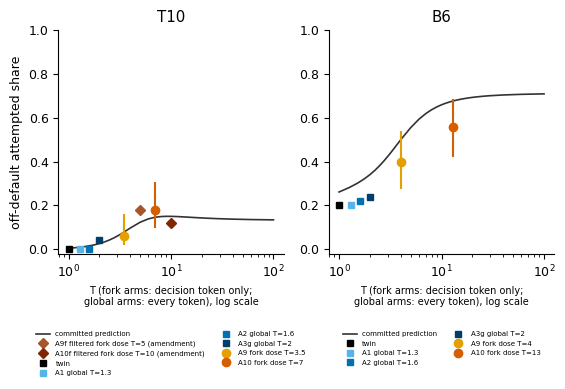

In [22]:
# src/figures8.py: setup and F1 (copied; changes marked "notebook:")
# matplotlib.use("Agg")      # notebook: removed, so that figures render inline
warnings.filterwarnings("ignore", message="Glyph .* missing from font")   # notebook: T10's token '父' has no glyph
plt.rcParams.update({"font.size": 9, "pdf.fonttype": 42, "ps.fonttype": 42, "axes.spines.top": False,
                     "axes.spines.right": False})
PAL = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#D55E00", "#F0E442", "#000000", "#999999", "#882255",
       "#44AA99", "#117733"]
ARM_COL = {"A0": "#000000", "A1": "#56B4E9", "A2": "#0072B2", "A3g": "#003f6b", "A4": "#999999", "A5": "#009E73",
           "A6": "#44AA99", "A7": "#CC79A7", "A8": "#882255", "A9": "#E69F00", "A10": "#D55E00", "A11": "#F0E442",
           "B1": "#117733", "A9f": "#a65628", "A10f": "#7f2704"}


def save(fig, name: str) -> None:
    fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{name}.png", dpi=170, bbox_inches="tight")
    plt.show()                # notebook: show inline (figures8.py: plt.close(fig))


def f1(c1, cells):
    units = [u for u, e in c1["units"].items() if e.get("role") not in (None, "boundary") and u in cells]
    if not units:
        return
    fig, axs = plt.subplots(1, len(units), figsize=(3.2 * len(units), 2.9), squeeze=False)
    for ax, u in zip(axs[0], units):
        e = c1["units"][u]
        Ts = sorted(float(t) for t in e["share_curve"])
        ax.plot(Ts, [e["share_curve"][str(t) if str(t) in e["share_curve"] else t] for t in Ts], color="#333333",
                lw=1.2, label="committed prediction")
        for a, T in (("A9", e["dose"]["d1"]), ("A10", e["dose"]["d2"])):
            if a in cells[u]:
                c = cells[u][a]
                x = round(c["off_default_attempted"] * c["n"])
                lo, hi = wilson(x, c["n"])
                ax.errorbar([T], [c["off_default_attempted"]], yerr=[[c["off_default_attempted"] - lo],
                                                                     [hi - c["off_default_attempted"]]],
                            fmt="o", color=ARM_COL[a], label=f"{a} fork dose T={T:g}")
        c3p = PRED_DIR / "commit3_amendment.json"
        if c3p.exists():
            e3 = read_json(c3p)["units"].get(u)
            for a in ("A9f", "A10f"):
                if e3 and a in cells[u]:
                    T = e3["arms"][a]["T"]
                    c = cells[u][a]
                    ax.plot([T], [c["off_default_attempted"]], "D", color=ARM_COL[a], ms=5,
                            label=f"{a} filtered fork dose T={T:g} (amendment)")
        for a, T in (("A0", 1.0), ("A1", 1.3), ("A2", 1.6), ("A3g", 2.0)):
            if a in cells[u]:
                ax.plot([T], [cells[u][a]["off_default_attempted"]], "s", color=ARM_COL[a], ms=5,
                        label=f"{a} global T={T:g}" if a != "A0" else "twin")
        ax.set_xscale("log")
        ax.set_title(u)
        ax.set_xlabel("T (fork arms: decision token only;\nglobal arms: every token), log scale", fontsize=7)
        ax.set_ylim(-0.02, 1.0)
        ax.legend(fontsize=5, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=2)
    axs[0][0].set_ylabel("off-default attempted share")
    save(fig, "F1_dose_response")


# figures8.main: the committed table, the observed rows (no adjudication) and the K1 cells written above
c1 = read_json(PRED_DIR / "commit1_dose_table.json")
obs = load_rows()             # notebook: figures8.main calls this `data`; renamed so the loaded JSON `data` is kept
cells = read_json(RESULTS_DIR / "k1_cells.json")
f1(c1, cells)

### F2: quality vs diversity

Each arm is a point at (pass cost against the twin, correct-only Hill-1 rarefied to 25), with a 2-sigma ellipse from `F2_BOOT` slot-bootstrap replicates. The dotted lines are the committed targets: Hill-1 >= 1.8 at pass cost <= 0.05. A sampler is a better creativity knob when it moves **up** (more distinct correct algorithms) without moving **right** (more broken programs).

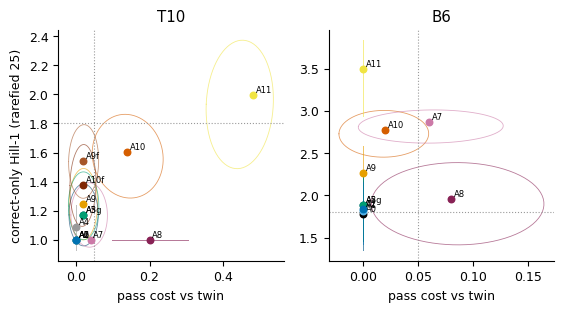

In [23]:
# src/figures8.py: F2 (copied; module prefix PR. dropped, the 200 bootstrap replicates are F2_BOOT)
def ellipse(ax, xs, ys, col):
    if len(xs) < 5:
        return
    cov = np.cov(xs, ys)
    if not np.all(np.isfinite(cov)):
        return
    vals, vecs = np.linalg.eigh(cov)
    t = np.linspace(0, 2 * np.pi, 80)
    circ = np.stack([np.cos(t), np.sin(t)])
    pts = vecs @ (np.sqrt(np.maximum(vals, 0))[:, None] * 2.0 * circ)
    ax.plot(np.mean(xs) + pts[0], np.mean(ys) + pts[1], color=col, lw=0.6, alpha=0.6)


def f2(data, cells):
    units = [u for u in cells if len(cells[u]) > 3]
    if not units:
        return
    fig, axs = plt.subplots(1, len(units), figsize=(3.2 * len(units), 3.0), squeeze=False)
    rng = np.random.default_rng(7)
    for ax, u in zip(axs[0], units):
        tw = data[u]["A0"]
        slots = sorted(tw)
        for a, c in cells[u].items():
            h = c["hill1_correct_r25"]
            if h is None:
                continue
            ax.scatter([c["pass_cost"]], [h], color=ARM_COL.get(a, "#777777"), s=22, zorder=3)
            ax.annotate(a, (c["pass_cost"], h), fontsize=6, xytext=(2, 2), textcoords="offset points")
            xs, ys = [], []
            for _ in range(F2_BOOT):                       # notebook: figures8.py uses range(200)
                idx = rng.integers(0, len(slots), len(slots))
                rr = [data[u][a].get(slots[i]) for i in idx]
                if any(r is None for r in rr):
                    break
                hh = hill1_rarefied([r["cls"] for r in rr if r["passed"]], 25)
                if hh is None:
                    continue
                xs.append(np.mean([tw[slots[i]]["passed"] for i in idx]) - np.mean([r["passed"] for r in rr]))
                ys.append(hh)
            ellipse(ax, np.array(xs), np.array(ys), ARM_COL.get(a, "#777777"))
        ax.axhline(1.8, ls=":", color="#999999", lw=0.8)
        ax.axvline(0.05, ls=":", color="#999999", lw=0.8)
        ax.set_title(u)
        ax.set_xlabel("pass cost vs twin")
    axs[0][0].set_ylabel("correct-only Hill-1 (rarefied 25)")
    save(fig, "F2_quality_diversity")


f2(obs, cells)

### F3 and F4: where the decision sits, and what each candidate token leads to

**F3** shows the histogram of the twin's T = 1 entropy at the decision token. The red line is q90 of all per-token entropies over generated steps 1-64. Prediction (c) said the decision token would usually sit *below* q90, inconspicuous by entropy. The opposite holds: code tokens are almost deterministic (q90 is tiny), and the decision token sits far above it in every slot. So an entropy-max rule can find the fork on mixed units (on B6, A7 is the decision position on 21/39 slots), but it finds it on only 2/50 slots of the collapsed T10.

**F4** shows the token map at each node. Bars are the algorithm shares of each top-20 candidate's 10 forced continuations. The black line is its log10 T = 1 mass, and red numbers give its failure rate. On T10, DFS-committal tokens (` visited`, ` graph`, ` adj`) sit 5-11 orders of magnitude behind ` parent`. Several candidates (`_parent`, `父`, ...) are format-breaking and fail 10/10.

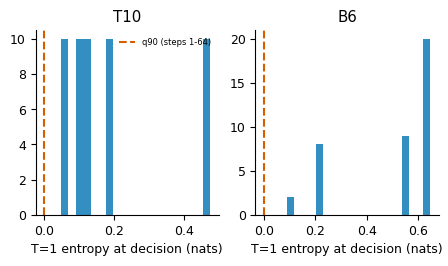

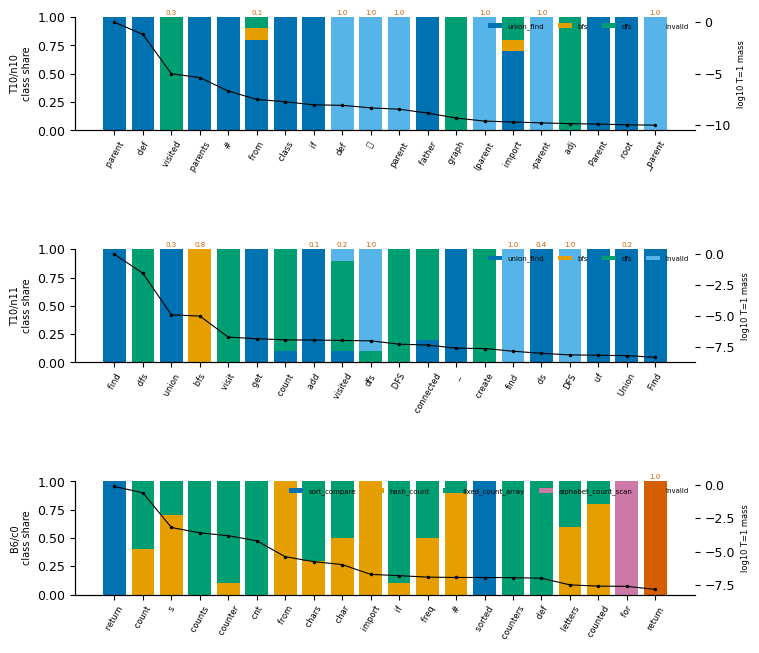

T10: q90 = 0.0008 nats; twin decision-token entropy below q90 in 0% of 50 slots; entropy-max position = decision on 2 slots
B6: q90 = 0.0003 nats; twin decision-token entropy below q90 in 0% of 39 slots; entropy-max position = decision on 21 slots


In [24]:
# src/figures8.py: F3, F4 (copied)
def f3(c1, data):
    units = [u for u, e in c1["units"].items() if e.get("q90") is not None and u in data]
    if not units:
        return
    fig, axs = plt.subplots(1, len(units), figsize=(2.6 * len(units), 2.4), squeeze=False)
    for ax, u in zip(axs[0], units):
        H = [r["decision_H1"] for r in data[u]["A0"].values() if r.get("decision_H1") is not None]
        ax.hist(H, bins=20, color="#0072B2", alpha=0.8)
        ax.axvline(c1["units"][u]["q90"], color="#D55E00", ls="--", label="q90 (steps 1-64)")
        ax.set_title(u)
        ax.set_xlabel("T=1 entropy at decision (nats)")
    axs[0][0].legend(fontsize=6, frameon=False)
    save(fig, "F3_decision_entropy")


def f4(c1):
    items = []
    for u, e in c1["units"].items():
        for nd, tm in (e.get("token_map") or {}).items():
            items.append((u, nd, tm))
        if e.get("token_map_n11"):
            items.append((u, "n11", e["token_map_n11"]))
    if not items:
        return
    fig, axs = plt.subplots(len(items), 1, figsize=(8, 2.5 * len(items)), squeeze=False)
    fig.subplots_adjust(hspace=1.05)
    for ax, (u, nd, tm) in zip(axs[:, 0], items):
        info = read_json(CACHE_DIR / "nodes" / f"{u}_{nd}.json")
        toks = info["map_tokens"][:20]
        cats = UNITS[u]["catalogue"] + ["other", "invalid"]
        x = np.arange(len(toks))
        bottom = np.zeros(len(toks))
        for ci, cname in enumerate(cats):
            v = np.array([tm.get(str(t), {}).get("counts", {}).get(cname, 0) / max(tm.get(str(t), {}).get("n", 1), 1)
                          for t in toks])
            if v.sum() == 0:
                continue
            ax.bar(x, v, bottom=bottom, color=PAL[ci % len(PAL)], label=cname, width=0.8)
            bottom += v
        p1 = [info["pooled_p20"].get(str(t), 0) for t in toks]
        ax2 = ax.twinx()
        ax2.plot(x, np.log10(np.maximum(p1, 1e-12)), "k.-", lw=0.8, ms=3)
        ax2.set_ylabel("log10 T=1 mass", fontsize=6)
        ax.set_xticks(x)
        ax.set_xticklabels([repr(info["map_token_str"].get(str(t), "?"))[1:-1][:10] for t in toks], rotation=60,
                           fontsize=6)
        ax.set_ylabel(f"{u}/{nd}\nclass share", fontsize=7)
        ax.legend(fontsize=5, frameon=False, ncol=6, loc="upper right")
        pf = [tm.get(str(t), {}).get("pfail", 0) for t in toks]
        for xi, f in zip(x, pf):
            if f > 0:
                ax.text(xi, 1.02, f"{f:.1f}", ha="center", fontsize=5, color="#D55E00")
    save(fig, "F4_token_maps")


f3(c1, obs)
f4(c1)
for u in DEMO_UNITS:
    print(f"{u}: q90 = {c1['units'][u]['q90']:.4f} nats; twin decision-token entropy below q90 in "
          f"{v['K1c'][u]['twin_dec_H_below_q90_frac']:.0%} of {v['K1c'][u]['n']} slots; entropy-max position = "
          f"decision on {v['K1c'][u]['A7_hits_decision']} slots")

### F7: CRN flip matrices

Every arm reuses each slot's uniforms, so for each slot one can ask: *the twin wrote algorithm X here; what did this arm write on the same random numbers?* Rows are the twin's class and columns the arm's class. Off-diagonal mass is a slot that *flipped*. Comparing the A9 / A10 panels with A1 / A3g separates idea changes made at the decision token from changes spread over the whole program.

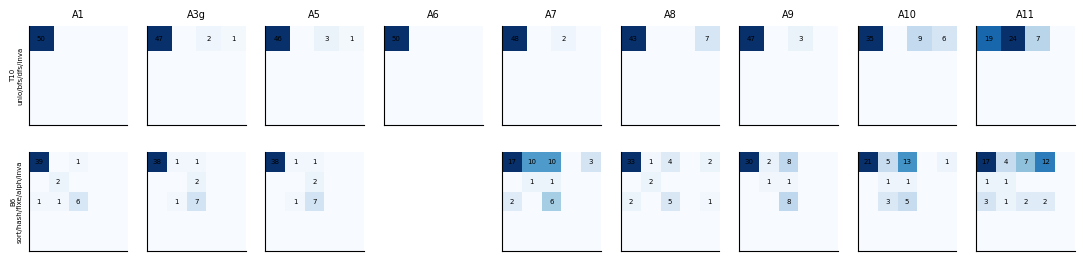

In [25]:
# src/figures8.py: F7 (copied)
def f7(data):
    units = [u for u in data if len(data[u]) > 3]
    if not units:
        return
    arms = ["A1", "A3g", "A5", "A6", "A7", "A8", "A9", "A10", "A11"]
    fig, axs = plt.subplots(len(units), len(arms), figsize=(1.5 * len(arms), 1.5 * len(units)), squeeze=False)
    for i, u in enumerate(units):
        cats = list(UNITS[u]["catalogue"]) + ["other", "invalid"]
        cats = [c for c in cats if any(r["cls"] == c for a in data[u] for r in data[u][a].values())]
        for j, a in enumerate(arms):
            ax = axs[i][j]
            ax.set_xticks([])
            ax.set_yticks([])
            if a not in data[u]:
                ax.axis("off")
                continue
            M = np.zeros((len(cats), len(cats)))
            for s, r in data[u][a].items():
                t = data[u]["A0"].get(s)
                if t and t["cls"] in cats and r["cls"] in cats:
                    M[cats.index(t["cls"]), cats.index(r["cls"])] += 1
            ax.imshow(M, cmap="Blues", vmin=0, vmax=max(M.max(), 1))
            for x in range(len(cats)):
                for y in range(len(cats)):
                    if M[y, x]:
                        ax.text(x, y, int(M[y, x]), ha="center", va="center", fontsize=5)
            if i == 0:
                ax.set_title(a, fontsize=7)
            if j == 0:
                ax.set_ylabel(u + "\n" + "/".join(c[:4] for c in cats), fontsize=5)
    save(fig, "F7_crn_flip_matrices")


f7(obs)

### F8: activation geometry (Qwen3-8B final-norm hidden states)

During decoding the engine stored, for every program, the **mean final-norm hidden state over the 16 positions from the decision token on** (4096-d for Qwen3-8B, float16, no extra forward pass). F8 shows a PCA of these states in actual activation coordinates, for the twin (A0), the fork-dosed arms (A9, A10), class-uniform forcing (A11) and global T (A1, A3g).
- Colour = the algorithm the finished program implements; marker = the arm.

**Nearest-centroid check.** Centroids come from the class-forced A11 slots, one per program class. Each fork-dosed slot is assigned to its nearest centroid, and the check asks whether that is its own program's class. If yes, the dose moves the model into its *own* region for that algorithm (on-manifold), rather than into a new region of activation space.

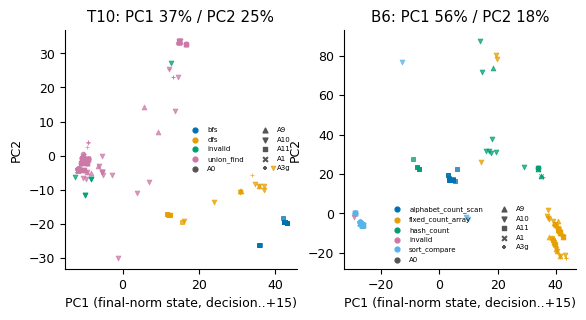

T10: 300 states, PC1+PC2 explain 62%; fork-dosed slots nearest to their own class centroid: 0.904 (n = 94) | artifact: 0.904 (n = 94)
B6: 233 states, PC1+PC2 explain 74%; fork-dosed slots nearest to their own class centroid: 0.831 (n = 77) | artifact: 0.831 (n = 77)


In [26]:
# src/figures8.py: F8 (copied)
def f8(data):
    """PCA of the mean final-norm hidden state over the 16 positions from the decision token."""
    H: dict[str, np.ndarray] = {}            # sid -> state (Qwen 4096-d, Gemma 2560-d: never mixed in one PCA)
    for f in sorted(glob.glob(str(CACHE_DIR / "hid" / "*.npz"))):
        z = np.load(f, allow_pickle=False)
        for s_, v in zip(z["sids"], z["H"]):
            H[str(s_)] = v.astype(np.float32)
    if not H:
        return {}
    idx = {s: s for s in H}
    out = {}
    units = [u for u in ("T10", "B3", "A3", "B6", "G", "T1") if u in data]
    fig, axs = plt.subplots(1, len(units), figsize=(3.3 * len(units), 3.1), squeeze=False)
    for ax, u in zip(axs[0], units):
        rows = [(a, r) for a in ("A0", "A9", "A10", "A11", "A1", "A3g") if a in data[u] for r in data[u][a].values()
                if r["sid"] in idx]
        if len(rows) < 10:
            ax.axis("off")
            continue
        X = np.stack([H[idx[r["sid"]]] for _, r in rows])
        mu = X.mean(0)
        U_, S_, Vt = np.linalg.svd(X - mu, full_matrices=False)
        ev = (S_ ** 2) / np.sum(S_ ** 2)
        P = (X - mu) @ Vt[:2].T
        cats = sorted({r["cls"] for _, r in rows})
        mk = {"A0": "o", "A9": "^", "A10": "v", "A11": "s", "A1": "x", "A3g": "+"}
        for (a, r), p in zip(rows, P):
            ax.scatter(p[0], p[1], marker=mk[a], s=12, color=PAL[cats.index(r["cls"]) % len(PAL)], alpha=0.75,
                       linewidths=0.6)
        for ci, c in enumerate(cats):
            ax.scatter([], [], color=PAL[ci % len(PAL)], label=c, s=12)
        for a, m in mk.items():
            ax.scatter([], [], marker=m, color="#555555", label=a, s=12)
        ax.set_title(f"{u}: PC1 {ev[0]:.0%} / PC2 {ev[1]:.0%}")
        ax.set_xlabel("PC1 (final-norm state, decision..+15)")
        ax.set_ylabel("PC2")
        ax.legend(fontsize=5, frameon=False, ncol=2)
        # nearest-centroid on-manifold check: centroids from class-forced (A11) slots by program label
        cent = {}
        for c in cats:
            pts = [H[idx[r["sid"]]] for a, r in rows if a == "A11" and r["cls"] == c]
            if len(pts) >= 2:
                cent[c] = np.mean(pts, 0)
        agree = n = 0
        for a, r in rows:
            if a in ("A9", "A10") and cent and r["cls"] in cent:
                d = {c: np.linalg.norm(H[idx[r["sid"]]] - v) for c, v in cent.items()}
                agree += int(min(d, key=d.get) == r["cls"])
                n += 1
        out[u] = {"explained_variance_pc1_pc2": ev[:2].tolist(), "n_states": len(rows),
                  "nearest_centroid_agreement_fork_dosed": agree / n if n else None, "n_fork_dosed_scored": n,
                  "centroid_classes": sorted(cent)}
    save(fig, "F8_activation_geometry")
    return out


geo = f8(obs)
write_json(RESULTS_DIR / "geometry_f8.json", geo)
for u, g in geo.items():
    r = ref["geometry_f8"][u]
    print(f"{u}: {g['n_states']} states, PC1+PC2 explain {sum(g['explained_variance_pc1_pc2']):.0%}; fork-dosed slots "
          f"nearest to their own class centroid: {g['nearest_centroid_agreement_fork_dosed']:.3f} "
          f"(n = {g['n_fork_dosed_scored']}) | artifact: {r['nearest_centroid_agreement_fork_dosed']:.3f} "
          f"(n = {r['n_fork_dosed_scored']})")

## 13. Results: every arm, side by side

One row per arm (50 CRN slots each), for both units, with these columns:
- the algorithms written (attempted counts);
- the pass rate;
- the correct-only Hill-1;
- the pass cost against the twin, with its Newcombe 95% CI;
- the number of distinct correct ideas;
- the number of distinct **phrasings** per idea (Jaccard >= 0.8 clusters).

The last two columns separate the two senses of "creative" sampling. A knob can produce *new phrasings of the same algorithm*, or *different algorithms*. A summary of the committed K1 tests on this two-unit subset follows the tables.

In [27]:
ARM_ORDER = ["A0", "A1", "A2", "A3g", "A4", "A5", "A6", "A7", "A8", "A9", "A10", "A9f", "A10f", "A11"]


def arm_desc(u: str, a: str) -> str:
    d = c1["units"][u]["dose"]
    c3u = read_json(PRED_DIR / "commit3_amendment.json")["units"].get(u, {}).get("arms", {})
    return {"A0": "twin, T = 1", "A1": "global T 1.3, top-p .95", "A2": "global T 1.6, top-p .95",
            "A3g": "global T 2.0, top-p .95", "A4": "min-p 0.1 at T 3", "A5": "EDT-style (T 2 if H > q90)",
            "A6": "AdapT-style (T 2 at block starts)", "A7": f"entropy-max position, T = {d['d2']:g}",
            "A8": f"random position, T = {d['d2']:g}", "A9": f"FORK dose d1 = {d['d1']:g} (decision token)",
            "A10": f"FORK dose d2 = {d['d2']:g} (decision token)",
            "A9f": f"filtered fork d1 = {c3u.get('A9f', {}).get('T', float('nan')):g} (amendment)",
            "A10f": f"filtered fork d2 = {c3u.get('A10f', {}).get('T', float('nan')):g} (amendment)",
            "A11": "class-uniform forcing"}.get(a, a)


def arm_table(u: str) -> pd.DataFrame:
    rows = []
    for a in [a for a in ARM_ORDER if a in v["cells"][u]]:
        c = v["cells"][u][a]
        rows.append({"arm": a, "sampler": arm_desc(u, a),
                     "programs written (attempted)": ", ".join(f"{k} {n}" for k, n in
                                                                sorted(c["counts"].items(), key=lambda kv: -kv[1])),
                     "pass": round(c["pass_rate"], 2),
                     "correct Hill-1": None if c["hill1_correct_r25"] is None else round(c["hill1_correct_r25"], 2),
                     "pass cost [95% CI]": f"{c['pass_cost']:+.2f} [{c['pass_cost_ci95'][0]:+.2f}, "
                                           f"{c['pass_cost_ci95'][1]:+.2f}]",
                     "correct ideas": len([k for k in c["correct_counts"] if k not in ("other", "invalid")]),
                     "phrasings per idea (J>=0.8)": ", ".join(f"{k} {p['0.8']}" for k, p in
                                                              c["phrasing_clusters"].items())})
    return pd.DataFrame(rows).set_index("arm")


pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 250)
for u in DEMO_UNITS:
    print(f"\n=== {u}: {UNITS[u]['task']} ({c1['units'][u]['role']}; the twin's default is {UNITS[u]['default']}) ===")
    display(arm_table(u))

# the committed K1 tests on this subset
K = v
print("\nK1 tests on the T10 + B6 subset")
for u in DEMO_UNITS:
    a_ = K["K1a"]["per_unit"][u]
    print(f"  (a) {u}: composed-prediction MAE {a_['mae']:.3f} (replay {a_['mae_replay']:.3f}) -> "
          f"{'PASS' if a_['pass'] else 'FAIL'} (threshold {THRESH['mae_max']})")
b_t10 = K["K1b"]["per_unit"]["T10"]
print(f"  (b) T10 collapsed: fork arms with Hill-1 >= 1.8 at cost <= 0.05: {b_t10['fork_arms_meeting_hill_and_cost']}; "
      f"comparator max Hill-1 {({f: round(x, 2) for f, x in b_t10['comparator_point_max_hill'].items()})}; "
      f"best-comparator bootstrap p = {b_t10['bootstrap']['best_comparator']['p_one_sided']:.3f} -> "
      f"{'PASS' if b_t10['pass'] else 'FAIL'}")
b_b6 = K["K1b"]["per_unit"]["B6"]
print(f"  (b) B6 mixed: d1 minority share {b_b6['d1_observed_minority']:.2f} vs target {b_b6['d1_target']:.2f} "
      f"(within 0.10: {b_b6['d1_within_0.10']}); best fork Hill-1 {b_b6['best_fork_hill']:.2f} (>= 1.8: "
      f"{b_b6['best_fork_hill'] >= THRESH['hill_min']}); fork vs best comparator p = "
      f"{b_b6['bootstrap']['best_comparator']['p_one_sided']:.3f}")
below = {u: K["K1c"][u]["twin_dec_H_below_q90_frac"] for u in DEMO_UNITS}
print(f"  (c) twin decision-token entropy below q90: " + ", ".join(f"{u} {x:.0%}" for u, x in below.items()) +
      f" (prediction: >= {THRESH['entropy_below_q90_frac']:.0%}) -> "
      f"{'PASS' if all(x >= THRESH['entropy_below_q90_frac'] for x in below.values()) else 'FAIL'}")
print(f"  (e) pooled reversion over T10 + B6: {K['K1e']['pooled_reversion']:.3f} of {K['K1e']['n_off_tokens']} "
      f"off-default decision tokens -> {'PASS' if K['K1e']['pass'] else 'FAIL'}")
print(f"  disconfirming branch 'pass cost > 0.10' fires: {K['disconfirming']['cost_above_0.10']} "
      f"(T10 fork pass costs {K['disconfirming']['values']['cost']})")
s_ = K["secondary_mcnemar_A10_vs_A3g"]["T10"]
print(f"  secondary: exact McNemar on correct off-default flips, T10 fork d2 vs global T 2.0: "
      f"{s_['b_A10_only']}:{s_['c_A3g_only']}, one-sided p = {s_['p_one_sided']:.3f}")


=== T10: connected components (collapsed; the twin's default is union_find) ===


,sampler,programs written (attempted),pass,correct Hill-1,pass cost [95% CI],correct ideas,phrasings per idea (J>=0.8)
arm,,,,,,,
A0,"twin, T = 1",union_find 50,1.00,1.00,"+0.00 [-0.07, +0.07]",1,union_find 3
A1,"global T 1.3, top-p .95",union_find 50,1.00,1.00,"+0.00 [-0.07, +0.07]",1,union_find 3
A2,"global T 1.6, top-p .95",union_find 50,1.00,1.00,"+0.00 [-0.07, +0.07]",1,union_find 4
A3g,"global T 2.0, top-p .95","union_find 47, dfs 2, invalid 1",0.98,1.17,"+0.02 [-0.05, +0.10]",2,"dfs 2, union_find 3"
A4,min-p 0.1 at T 3,"union_find 49, dfs 1",1.00,1.09,"+0.00 [-0.07, +0.07]",2,"dfs 1, union_find 3"
A5,EDT-style (T 2 if H > q90),"union_find 47, dfs 2, invalid 1",0.98,1.17,"+0.02 [-0.05, +0.10]",2,"dfs 2, union_find 3"
A6,AdapT-style (T 2 at block starts),union_find 50,1.00,1.00,"+0.00 [-0.07, +0.07]",1,union_find 3
A7,"entropy-max position, T = 7",union_find 50,0.96,1.00,"+0.04 [-0.04, +0.13]",1,union_find 3
A8,"random position, T = 7","union_find 43, invalid 7",0.80,1.00,"+0.20 [+0.09, +0.33]",1,union_find 4



=== B6: valid anagram (mixed; the twin's default is sort_compare) ===


,sampler,programs written (attempted),pass,correct Hill-1,pass cost [95% CI],correct ideas,phrasings per idea (J>=0.8)
arm,,,,,,,
A0,"twin, T = 1","sort_compare 40, fixed_count_array 8, hash_count 2",1.00,1.78,"+0.00 [-0.07, +0.07]",3,"fixed_count_array 2, hash_count 1, sort_compare 2"
A1,"global T 1.3, top-p .95","sort_compare 40, fixed_count_array 7, hash_count 3",1.00,1.82,"+0.00 [-0.07, +0.07]",3,"fixed_count_array 2, hash_count 1, sort_compare 2"
A2,"global T 1.6, top-p .95","sort_compare 39, fixed_count_array 9, hash_count 2",1.00,1.83,"+0.00 [-0.07, +0.07]",3,"fixed_count_array 3, hash_count 1, sort_compare 2"
A3g,"global T 2.0, top-p .95","sort_compare 38, fixed_count_array 10, hash_count 2",1.00,1.89,"+0.00 [-0.07, +0.07]",3,"fixed_count_array 3, hash_count 1, sort_compare 2"
A5,EDT-style (T 2 if H > q90),"sort_compare 38, fixed_count_array 10, hash_count 2",1.00,1.89,"+0.00 [-0.07, +0.07]",3,"fixed_count_array 4, hash_count 1, sort_compare 2"
A7,"entropy-max position, T = 13","sort_compare 19, fixed_count_array 17, hash_count 11, invalid 3",0.94,2.87,"+0.06 [-0.02, +0.16]",3,"fixed_count_array 6, hash_count 6, sort_compare 3"
A8,"random position, T = 13","sort_compare 35, fixed_count_array 9, invalid 3, hash_count 3",0.92,1.95,"+0.08 [-0.01, +0.19]",3,"fixed_count_array 3, hash_count 3, sort_compare 2"
A9,FORK dose d1 = 4 (decision token),"sort_compare 30, fixed_count_array 17, hash_count 3",1.00,2.27,"+0.00 [-0.07, +0.07]",3,"fixed_count_array 6, hash_count 2, sort_compare 2"
A10,FORK dose d2 = 13 (decision token),"sort_compare 21, fixed_count_array 19, hash_count 9, invalid 1",0.98,2.78,"+0.02 [-0.05, +0.10]",3,"fixed_count_array 5, hash_count 3, sort_compare 3"



K1 tests on the T10 + B6 subset
  (a) T10: composed-prediction MAE 0.017 (replay 0.013) -> PASS (threshold 0.1)
  (a) B6: composed-prediction MAE 0.047 (replay 0.031) -> PASS (threshold 0.1)
  (b) T10 collapsed: fork arms with Hill-1 >= 1.8 at cost <= 0.05: []; comparator max Hill-1 {'global_T': 1.17, 'min_p': 1.09, 'EDT': 1.17, 'AdapT': 1.0}; best-comparator bootstrap p = 0.301 -> FAIL
  (b) B6 mixed: d1 minority share 0.40 vs target 0.50 (within 0.10: True); best fork Hill-1 2.78 (>= 1.8: True); fork vs best comparator p = 0.008
  (c) twin decision-token entropy below q90: T10 0%, B6 0% (prediction: >= 90%) -> FAIL
  (e) pooled reversion over T10 + B6: 0.000 of 15 off-default decision tokens -> PASS
  disconfirming branch 'pass cost > 0.10' fires: True (T10 fork pass costs [0.02, 0.14])
  secondary: exact McNemar on correct off-default flips, T10 fork d2 vs global T 2.0: 7:1, one-sided p = 0.035


### Summary figure: ideas vs phrasings per arm

**Top row:** which algorithms each sampler writes on the same 50 CRN slots (attempted shares; grey = invalid), with the correct-only Hill-1 above each bar.

**Bottom row:** how many distinct *phrasings* each correct idea has. These are connected components of identifier-normalised token 4-gram Jaccard similarity >= 0.8, from `analysis_k1.phrasing_clusters`. The number above each bar is the number of correct programs.

Global temperature (A1-A3g) mostly re-phrases the default algorithm. The decision-token doses (A9 / A10) change the algorithm, and the phrasings multiply with the new ideas.


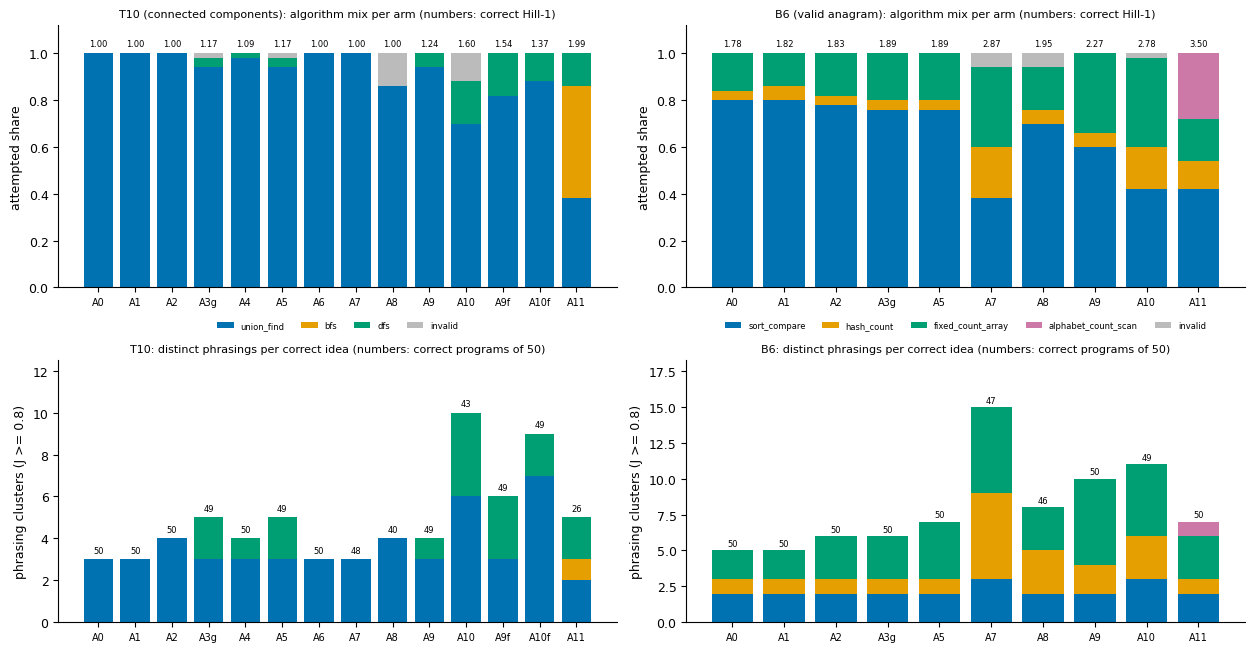

figures written to k1_demo_root/figures : ['F1_dose_response.png', 'F2_quality_diversity.png', 'F3_decision_entropy.png', 'F4_token_maps.png', 'F7_crn_flip_matrices.png', 'F8_activation_geometry.png', 'summary_ideas_vs_phrasings.png']


In [28]:
# notebook: summary figure, ideas (algorithm mix) vs phrasings per arm
fig, axs = plt.subplots(2, len(DEMO_UNITS), figsize=(6.4 * len(DEMO_UNITS), 6.6), squeeze=False)
for j, u in enumerate(DEMO_UNITS):
    cu = v["cells"][u]
    arms = [a for a in ARM_ORDER if a in cu]
    allc = classes_of(u)
    cats = [c for c in allc if any(cu[a]["counts"].get(c, 0) for a in arms)]
    x = np.arange(len(arms))
    # top: which algorithms each sampler writes (attempted shares), correct Hill-1 on top
    ax = axs[0][j]
    bottom = np.zeros(len(arms))
    for c in cats:
        vals = np.array([cu[a]["attempted"].get(c, 0) for a in arms])
        ax.bar(x, vals, bottom=bottom, color=PAL[allc.index(c) % len(PAL)] if c != "invalid" else "#bbbbbb",
               label=c, width=0.8)
        bottom += vals
    for xi, a in zip(x, arms):
        h = cu[a]["hill1_correct_r25"]
        ax.text(xi, 1.03, f"{h:.2f}" if h is not None else "NA", ha="center", fontsize=6)
    ax.set_xticks(x)
    ax.set_xticklabels(arms, fontsize=7)
    ax.set_ylim(0, 1.12)
    ax.set_ylabel("attempted share")
    ax.set_title(f"{u} ({UNITS[u]['task']}): algorithm mix per arm (numbers: correct Hill-1)", fontsize=8)
    ax.legend(fontsize=6, frameon=False, ncol=len(cats), loc="upper center", bbox_to_anchor=(0.5, -0.1))
    # bottom: distinct phrasings of each correct idea (identifier-normalised 4-gram Jaccard >= 0.8 clusters)
    ax = axs[1][j]
    bottom = np.zeros(len(arms))
    for c in [c for c in cats if c not in ("invalid",)]:
        vals = np.array([cu[a]["phrasing_clusters"].get(c, {}).get("0.8", 0) for a in arms], dtype=float)
        if vals.sum() == 0:
            continue
        ax.bar(x, vals, bottom=bottom, color=PAL[allc.index(c) % len(PAL)], label=c, width=0.8)
        bottom += vals
    for xi, a in zip(x, arms):
        ax.text(xi, bottom[xi] + 0.3, str(cu[a]["n_correct"]), ha="center", fontsize=6)
    ax.set_xticks(x)
    ax.set_xticklabels(arms, fontsize=7)
    ax.set_ylim(0, max(bottom) * 1.15 + 1)
    ax.set_ylabel("phrasing clusters (J >= 0.8)")
    ax.set_title(f"{u}: distinct phrasings per correct idea (numbers: correct programs of 50)", fontsize=8)
plt.tight_layout()
fig.savefig(FIG_DIR / "summary_ideas_vs_phrasings.png", dpi=150, bbox_inches="tight")
plt.show()
print("figures written to", FIG_DIR, ":", sorted(p.name for p in FIG_DIR.glob("*.png")))

## 14. What the replay shows

Every number below, apart from the HR count at the end, was re-computed in this notebook from the stored programs. Each matches the artifact's own results to the last digit (see the check cells above).

- **The dial is predictable.**
  - The committed composition of the decision token's teacher-forced logits with its token map, computed before any arm was sampled, names the algorithm mix of the dosed cells to an MAE of **0.017 (T10)** and **0.047 (B6)**.
  - The per-slot replay names the dosed token itself: 14 of the 16 B6 slots whose token changes at d1. It works by pushing each slot's own uniform through the dosed top-20 inverse CDF.
- **Where the alternative is already in play (B6), temperature at one token sets the mix.**
  - Correct-program diversity rises from Hill-1 **1.78** (twin) to **2.27** at d1 = 4 and **2.78** at d2 = 13, at a pass cost of at most 2 points.
  - Global temperature 1.3-2.0 and EDT stay at or below 1.89.
  - The paired bootstrap against the best comparator family gives lower bound +0.19, p = 0.008.
- **Where the model has collapsed (T10), the dial reaches what global temperature cannot, but only a little.**
  - DFS rises to 3/50 at d1 and 9/50 at d2, against 0 for global T 1.3 / 1.6 and 2 for T 2.0. The exact McNemar on correct off-default flips, d2 vs T 2.0, is 7:1, p = 0.035.
  - But correct Hill-1 stays at 1.24 / 1.60, and d2 costs 14 pass points. Several of the 20 candidates break the program format (`_parent`, `父`, ...).
  - So the committed K1(b) test **fails** (bootstrap p = 0.30), and the pass-cost disconfirming branch fires.
  - The amendment that drops the breaking candidates (A9f) keeps the pass rate at 0.98 with DFS 9/50, which is still only Hill-1 1.54.
- **Ideas vs phrasings.** Global temperature mostly rewrites the *same* algorithm.
  - On B6 the twin's correct programs fall into 5 phrasing clusters; global T 1.3-2.0 gives 5-6, the fork doses give 10-11.
  - On T10 the twin has 3 union-find phrasings; the d2 dose gives 6 union-find plus 4 DFS phrasings.
  - Changing the decision token changes the idea, and the phrasings multiply with it.
- **No new regions of activation space.** Qwen3-8B's post-decision hidden states cluster by the algorithm the program implements. Fork-dosed slots land in their own algorithm's cluster: the nearest class-forced centroid is their own class for 0.90 of T10 slots and 0.83 of B6 slots.
- **Entropy is not what hides the fork; collapse is.**
  - The decision token's entropy is far above q90 in every slot, so prediction (c) fails.
  - An entropy-max rule therefore finds the fork on B6 (21 of 39 slots), but on only 2 of 50 slots on the collapsed T10.

**Bottom line (the artifact's answer to "is temperature the creativity knob?").** Temperature applied at the token where the model commits to an algorithm is a precise, predictable dial between algorithms the model already has. It does not create new ones. The artifact's HR stage forced every top-64 branch of each decision token and found 0 novel algorithms among 5,543 correct programs (not replayed here).

**Scaling up.**
- The config cell already uses the artifact's original bootstrap and Monte-Carlo sizes.
- The other units (B3, A3, G and the boundary units T1 / T2 / T03) and the HR, locator and novelty stages need the full artifact data (`data/*.jsonl`, `cache/`, `predictions/`) and its GPU stages. Run them with `python method.py all` on a CUDA GPU with at least 20 GB.
- `tools/build_mini_demo_data.py` documents how this subset was cut from the artifact.
